# Multi-Fidelity Mapping for MC Neutronics Simulations: from low to high statistics
This notebook adopts a Shallow Decoder Networks for Multi-Fidelity (MF) mapping, aiming at estimating the HF solution using very few HF samples.

Let us report here the computational cost of the simulations (wall-clock time with 14 cores):
- Low Stats (2500 particles): 1.1736 min / simulation
- High Stats (100000 particles): 31.33 min / simulation

In [ ]:
# from matplotlib import rcParams
# rcParams.update({
#   "text.usetex": True,
#   "font.family": "serif"
# })

# rcParams['text.latex.preamble'] = r'\usepackage{amssymb} \usepackage{amsmath} \usepackage{amsthm} \usepackage{mathtools}'

import os
path_res = os.path.join(os.getcwd(), 'Results/MultiFidelity/')
os.makedirs(path_res, exist_ok=True)

A 2 step approach is adopted:
1. Train the SDN for the LF solution searching for the relation between the parameters $\boldsymbol{\mu}$, few measurements to the full LF solution, exploiting the SVD. The predicted state vector $\hat{\mathbf{u}}$ is defined as, where $\hat{\mathbf{v}}$ is the output of the SDN
$$\mathbf{u}_{LF} \approx \hat{\mathbf{u}}_{LF} = \mathbb{U}_{LF}\hat{\mathbf{v}}_{LF} = \mathbb{U}_{LF}\mathbf{f}_{SDN}(\boldsymbol{\mu})$$
2. Learn the discrepancy between the LF and HF solutions using a residual SDN, where the input is the LF solution $\hat{\mathbf{u}}_{LF}$ and the output is the HF solution $\mathbf{u}_{HF}$
$$\mathbf{u}_{HF} \approx \hat{\mathbf{u}}_{HF} = \hat{\mathbf{u}}_{LF} + \hat{\delta} = \hat{\mathbf{u}}_{LF} + \mathbf{f}_{res}(\hat{\mathbf{v}}_{LF}, \boldsymbol{\mu})$$


In [2]:
import torch
from utils.sdn import ShallowDecoderNetwork, MyDataset, fit

# Set the device
device = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')

## Step 1: training the SDN for the LF
At first, a surrogate model for the LF (low statistics) is trained.

In [4]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
# from sklearn.utils.extmath import randomized_svd

# Load the low statistics (LF) flux data
_tmp = np.load(f'Data/flux_data_lowstats400.npz', allow_pickle=True)

lf_snaps = _tmp['flux']
lf_params = _tmp['params']
lf_centroids = _tmp['centroids']

del _tmp

def train_sdn_lf():

    # Define the sensors in the domain
    xmin, xmax = -20, 20
    ymin, ymax = -20, 20
    zmin, zmax = 20.0, 50.0

    mask = (
        (lf_centroids[:, 0] >= xmin) & (lf_centroids[:, 0] <= xmax) &
        (lf_centroids[:, 1] >= ymin) & (lf_centroids[:, 1] <= ymax) &
        (lf_centroids[:, 2] >= zmin) & (lf_centroids[:, 2] <= zmax)
    )

    cell_indices = np.where(mask)[0] 

    np.random.seed(60)
    n_sensors = 4
    idx_sens_locs = np.random.choice(cell_indices, size=n_sensors, replace=False)

    # Split the LF data into training, validation and testing sets
    train_indices, test_indices, train_params, test_params = train_test_split(np.arange(len(lf_params)), lf_params, test_size=0.3, random_state=42)

    valid_indices = test_indices[::2]
    test_indices = test_indices[1::2]

    valid_params = test_params[::2]
    test_params = test_params[1::2]

    max_flux = lf_snaps[:, train_indices].max()

    train_data = lf_snaps[:, train_indices] / max_flux
    test_data  = lf_snaps[:, test_indices]  / max_flux
    valid_data = lf_snaps[:, valid_indices] / max_flux

    # Perform SVD on the LF data
    rank = 5
    # modes, _, _ = randomized_svd(train_data, n_components=rank, n_iter='auto')
    modes, _, _ = np.linalg.svd(train_data, full_matrices=False)
    modes = modes[:, :rank]

    # Define input vector for the SDN
    # train_input = np.concatenate([train_data[idx_sens_locs], lf_params[train_indices].T], axis=0)
    # test_input  = np.concatenate([test_data[idx_sens_locs],  lf_params[test_indices].T],  axis=0)
    # valid_input = np.concatenate([valid_data[idx_sens_locs], lf_params[valid_indices].T], axis=0)
    train_input = lf_params[train_indices].T
    test_input  = lf_params[test_indices].T
    valid_input = lf_params[valid_indices].T

    input_scaler = MinMaxScaler()
    input_scaler.fit(train_input.T)

    train_input = input_scaler.transform(train_input.T).T
    test_input  = input_scaler.transform(test_input.T).T
    valid_input = input_scaler.transform(valid_input.T).T

    # Define the dataset
    compressive_training = True
    train_dataset = MyDataset(torch.tensor(train_input.T, dtype=torch.float32).to(device), torch.tensor(train_data.T, dtype=torch.float32).to(device))
    test_dataset  = MyDataset(torch.tensor(test_input.T, dtype=torch.float32).to(device),  torch.tensor(test_data.T, dtype=torch.float32).to(device))
    valid_dataset = MyDataset(torch.tensor(valid_input.T, dtype=torch.float32).to(device), torch.tensor(valid_data.T, dtype=torch.float32).to(device))

    # Define the SDN
    in_dim = train_input.shape[0]
    out_dim = rank if compressive_training else train_data.shape[0]
    pod_modes = torch.tensor(modes, dtype=torch.float32).to(device) if compressive_training else None

    sdn = ShallowDecoderNetwork(in_dim = in_dim, out_dim=out_dim, dropout=0.1, decoder_sizes=[350,400], 
                                pod_modes=pod_modes).to(device)

    # Fit the SDN
    fit(model=sdn, train_dataset=train_dataset, valid_dataset=valid_dataset, 
        batch_size=32, epochs=1000, patience=30,
        optim=torch.optim.Adam, criterion=torch.nn.L1Loss(), lr=0.001, 
        verbose=True)
    
    # Freeze the network parameters
    sdn.freeze()

    # Return the trained SDN, input scaler, modes, sensor locations, test dataset, test indices, and max flux (normalisation factor)
    return sdn, input_scaler, modes, idx_sens_locs, test_dataset, test_indices, max_flux

lf_sdn, lf_input_scaler, lf_modes, lf_idx_sens_locs, lf_test_dataset, lf_test_indices, lf_max_flux = train_sdn_lf()

Training done: Training MRE = 3.69% 	 Validation MRE = 3.73%      


Let us make some plots of the results of the LF simulations.

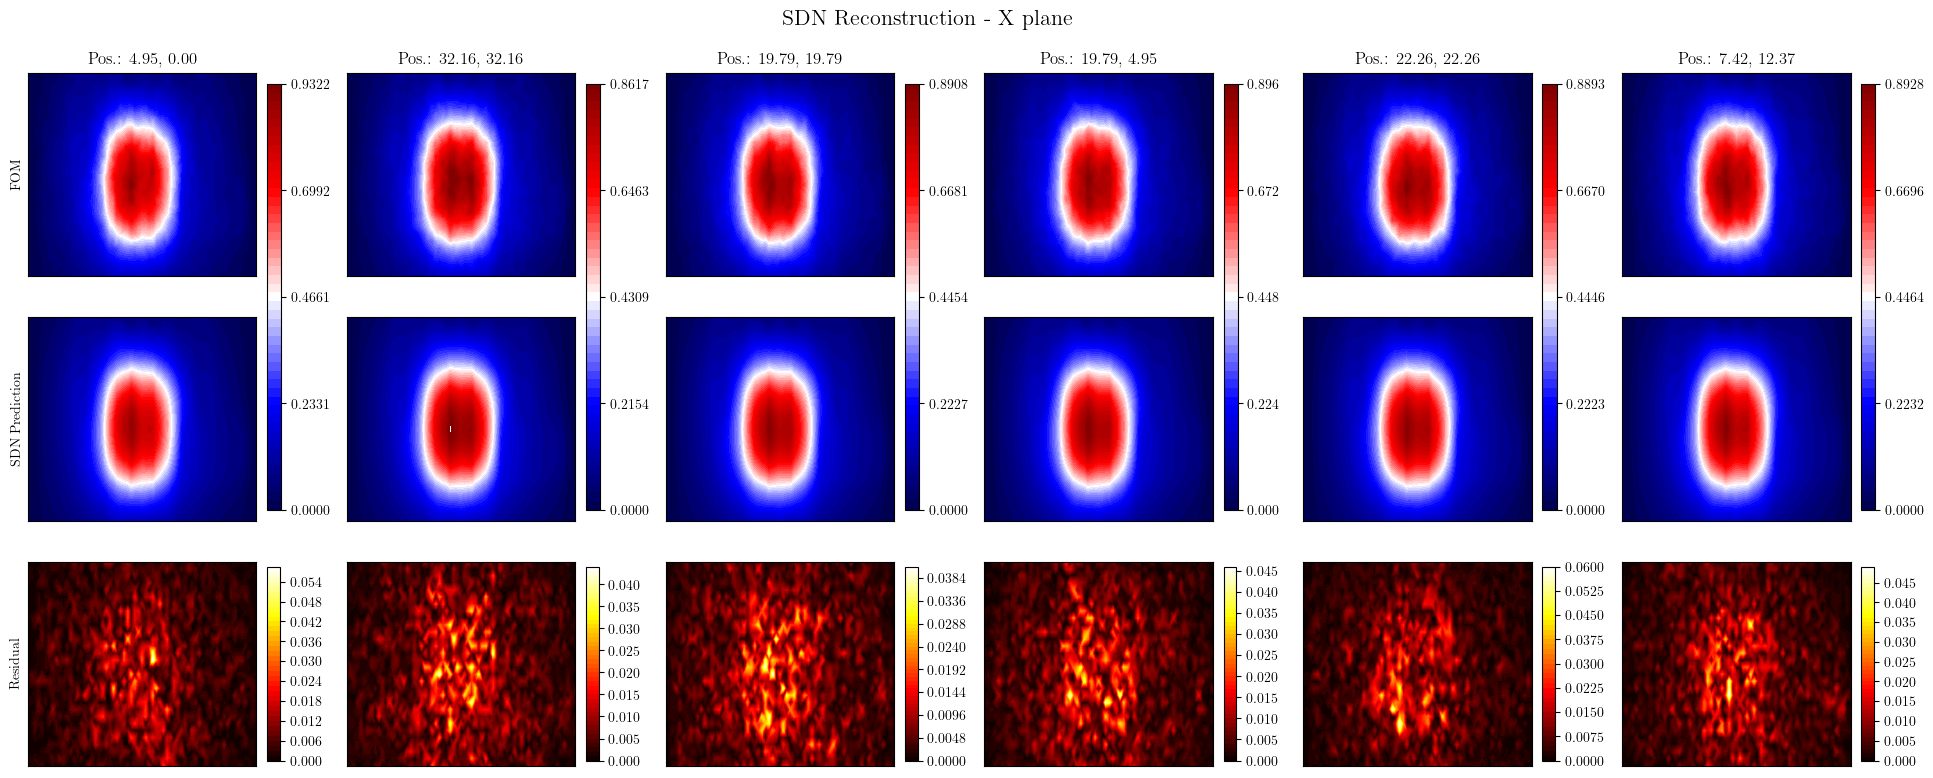

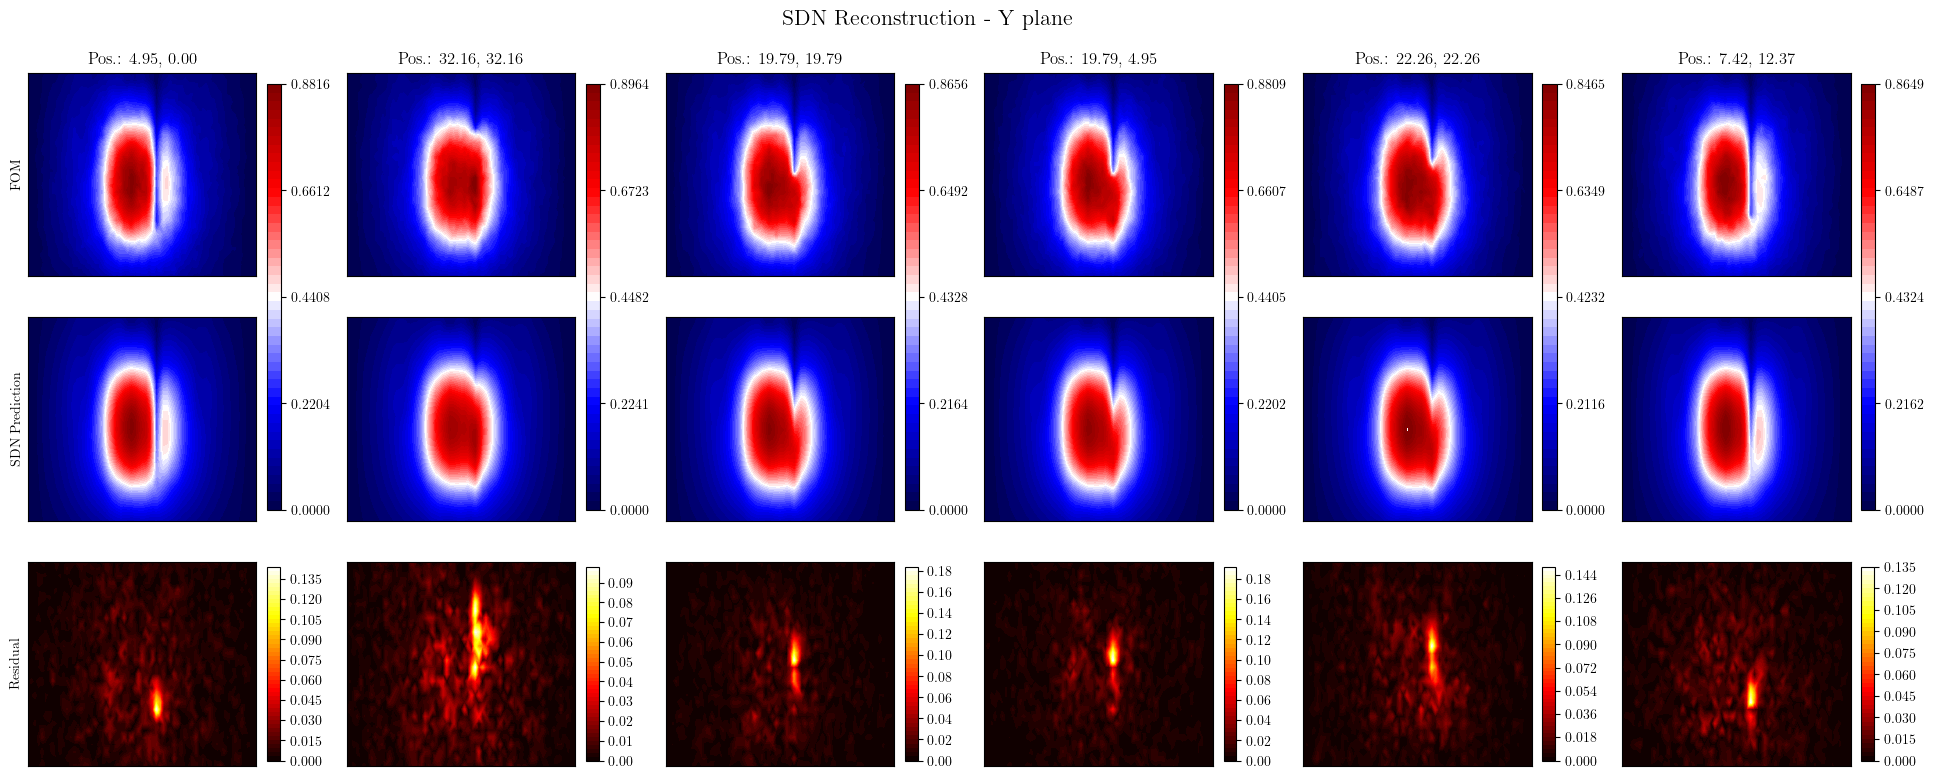

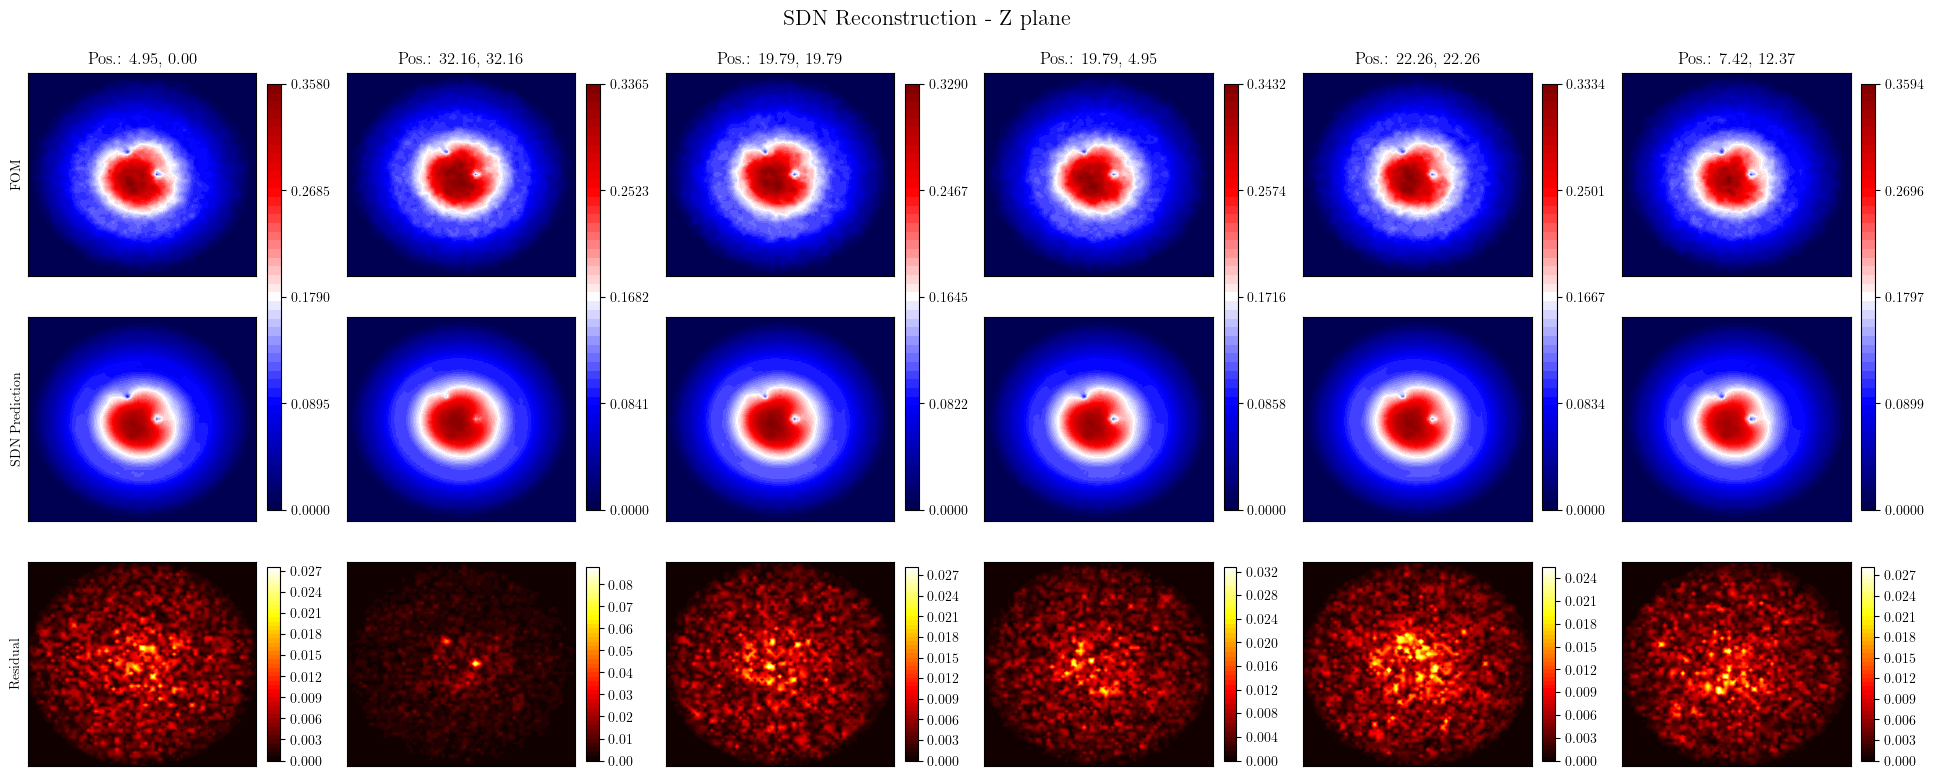

In [5]:
from utils.plots import PlotTriga
import pyvista as pv
from matplotlib import cm
import matplotlib.pyplot as plt

pl = PlotTriga(pv.read(f'Data/mesh_lowstats400.vtk'))

cmap = cm.seismic
cmap_res = cm.hot

nrows = 3
ncols = 6

for normal in ['x', 'y', 'z']:

    fig, axs = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows))

    for ii in range(len(axs[0])):
        fom = lf_test_dataset.Y.cpu().numpy()[ii]
        model_pred = lf_sdn(lf_test_dataset.X[ii]).cpu().detach().numpy()
        residual = np.abs(fom - model_pred)

        _slice_fom = pl.get_slice(fom, name='fom', plane_normal=normal)[1]

        levels = np.linspace(0, np.max(_slice_fom), 50)
        cont = pl.plot_slice(axs[0, ii], fom, normal=normal, levels=levels, cmap=cmap)
        pl.plot_slice(axs[1, ii], model_pred, normal=normal, levels=levels, cmap=cmap)
        res_cont = pl.plot_slice(axs[2, ii], residual, normal=normal, levels=len(levels), cmap=cmap_res)

        cbar = fig.colorbar(cont, ax=axs[:2,ii], orientation='vertical', fraction=0.1, pad=0.04, shrink=0.95, aspect=30)
        cbar.ax.set_yticks(np.linspace(0, levels.max(), 5))

        cbar_res = fig.colorbar(res_cont, ax=axs[2,ii], orientation='vertical', fraction=0.1, pad=0.04, shrink=0.95, aspect=15)

        # Set titles 
        axs[0, ii].set_title('Pos.: {:.2f}, {:.2f}'.format(*lf_params[lf_test_indices[ii]]))

    for ax in axs.flatten():
        ax.set_xticks([])
        ax.set_yticks([])
        
    axs[0, 0].set_ylabel('FOM')
    axs[1, 0].set_ylabel('SDN Prediction')
    axs[2, 0].set_ylabel('Residual')
    fig.suptitle(f'SDN Reconstruction - {normal.upper()} plane', fontsize=16, y=0.95)

    plt.show()
    

### Accuracy assessment with respect to the HF solution
Let us import the HF data and the LF for the corresponding parameters, and plot the results.

**This code assumes that the mesh for HF and LF is the same.**

In [6]:
# Load the high statistics (HF) flux data
_tmp = np.load(f'Data/flux_data_highstats.npz', allow_pickle=True)   

hf_snaps = _tmp['flux']
hf_params = _tmp['params']
hf_centroids = _tmp['centroids']

# Load the low statistics (LF) flux data - same parameters as HF
_tmp = np.load(f'Data/flux_data_lowstats121.npz', allow_pickle=True)
lf_snaps_comparison = _tmp['flux']
lf_params_comparison = _tmp['params']
lf_centroids_comparison = _tmp['centroids']

del _tmp

For this new set of parameters/simulations, let us predict the SDN output and compare it with the HF solution.

In [7]:
# _input = np.concatenate([lf_snaps_comparison[lf_idx_sens_locs] / lf_max_flux, lf_params_comparison.T], axis=0)
_input = lf_params_comparison.T
_input = lf_input_scaler.transform(_input.T).T
_input = torch.tensor(_input, dtype=torch.float32).to(device).T

# Predict the SDN output for the new parameters
lf_sdn_pred = lf_sdn(_input).cpu().detach().numpy().T

Let us compare the predicted LF solution with the HF solution, and the LF solution

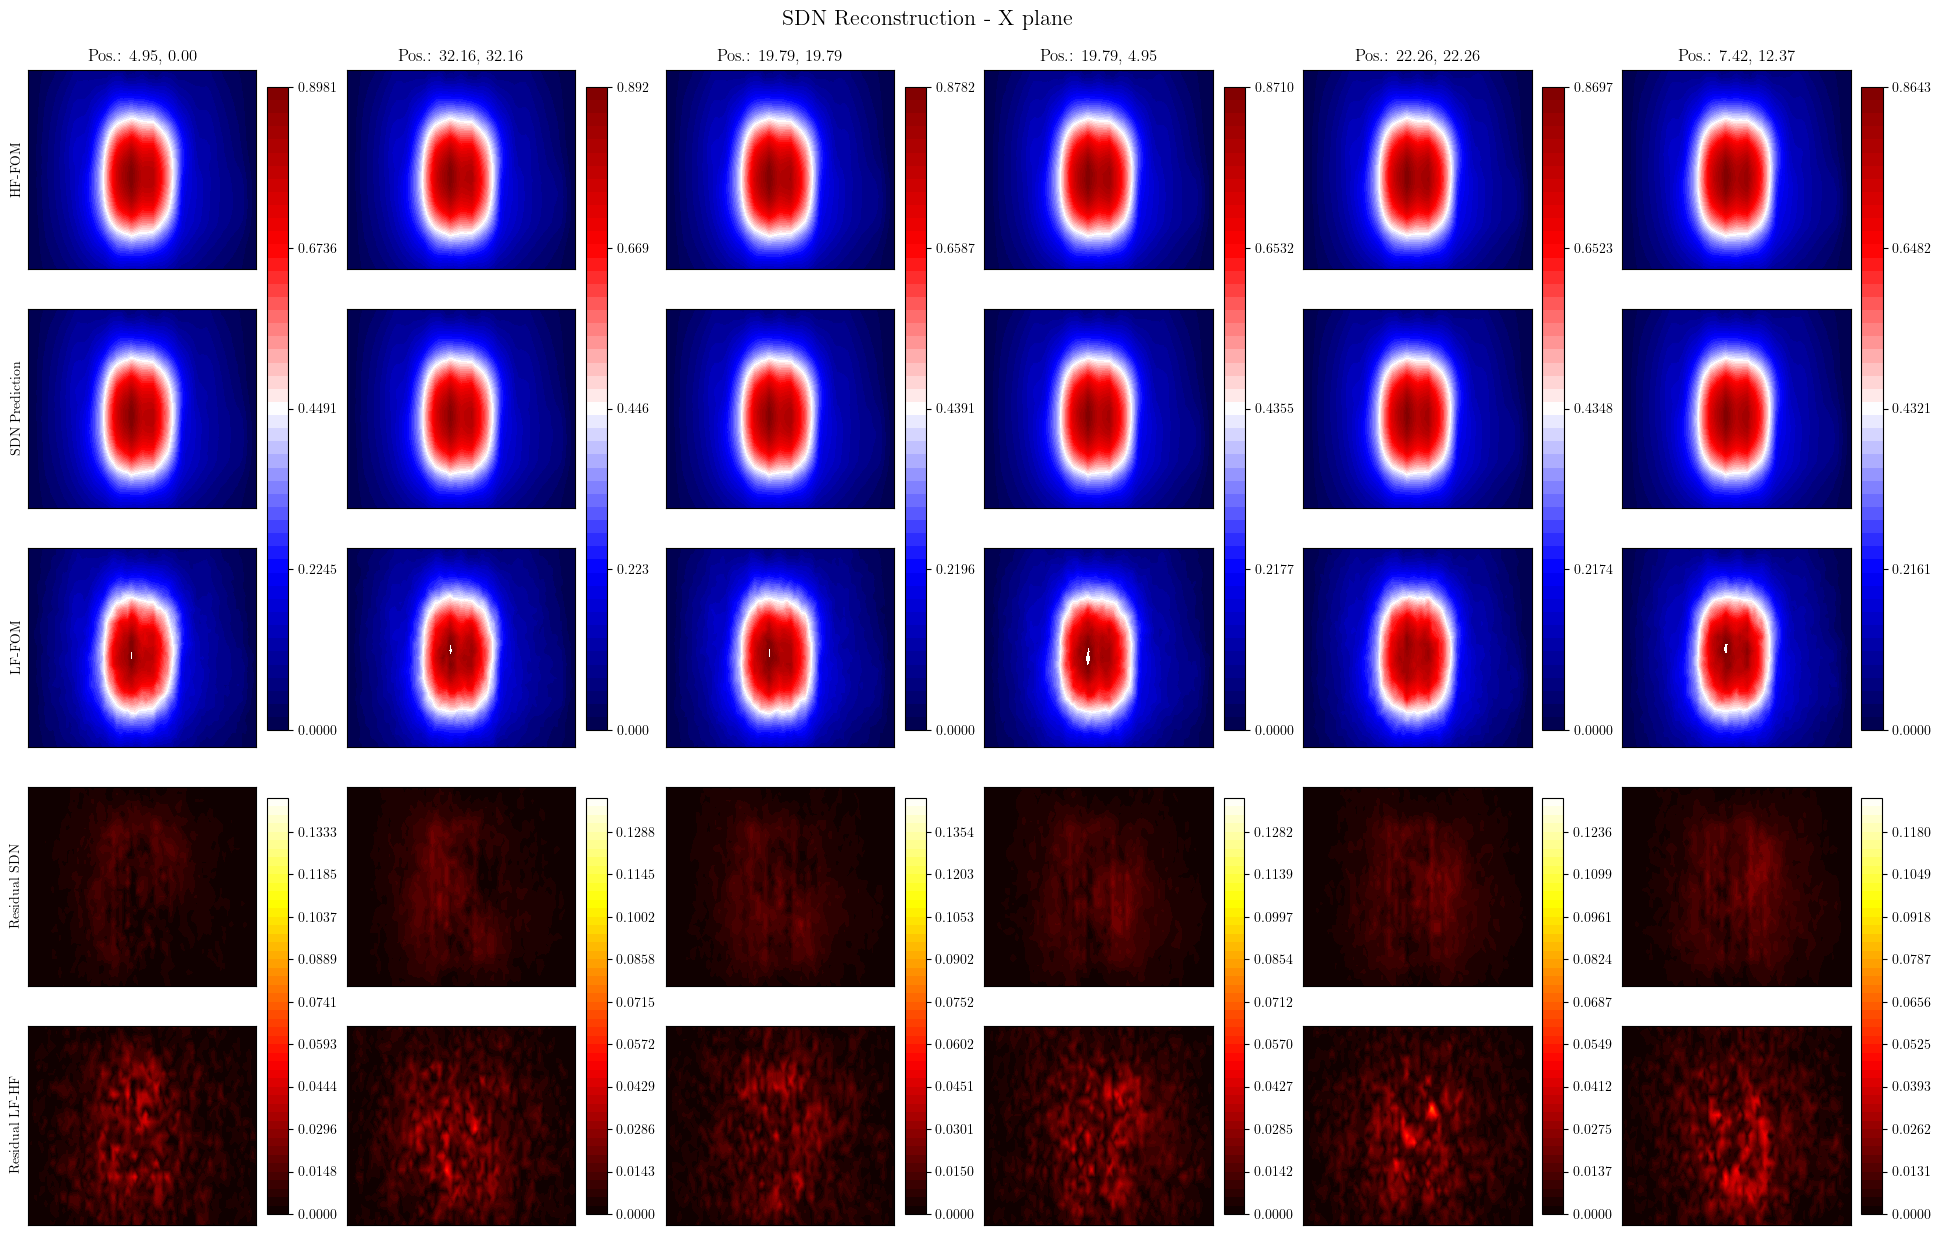

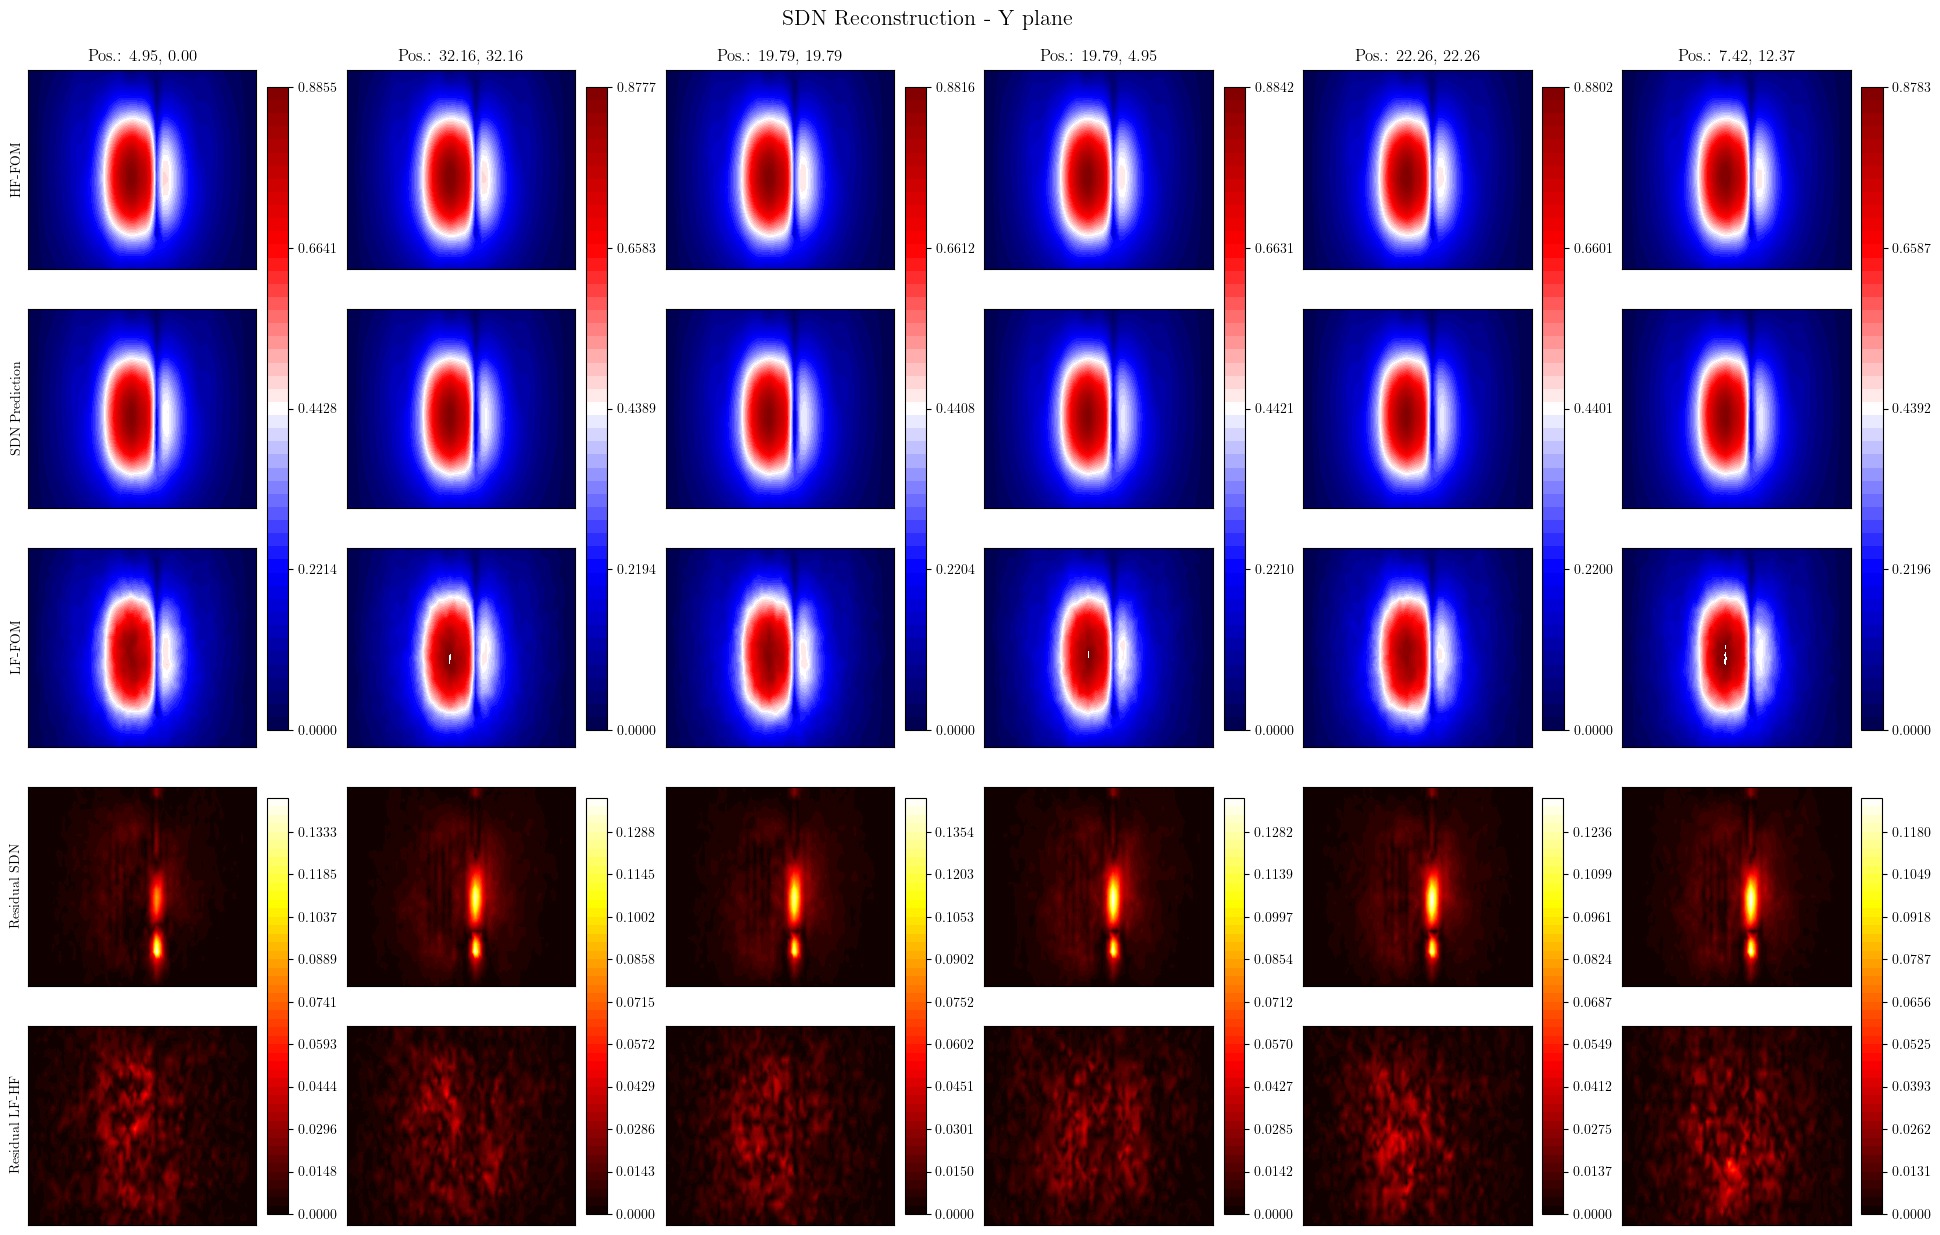

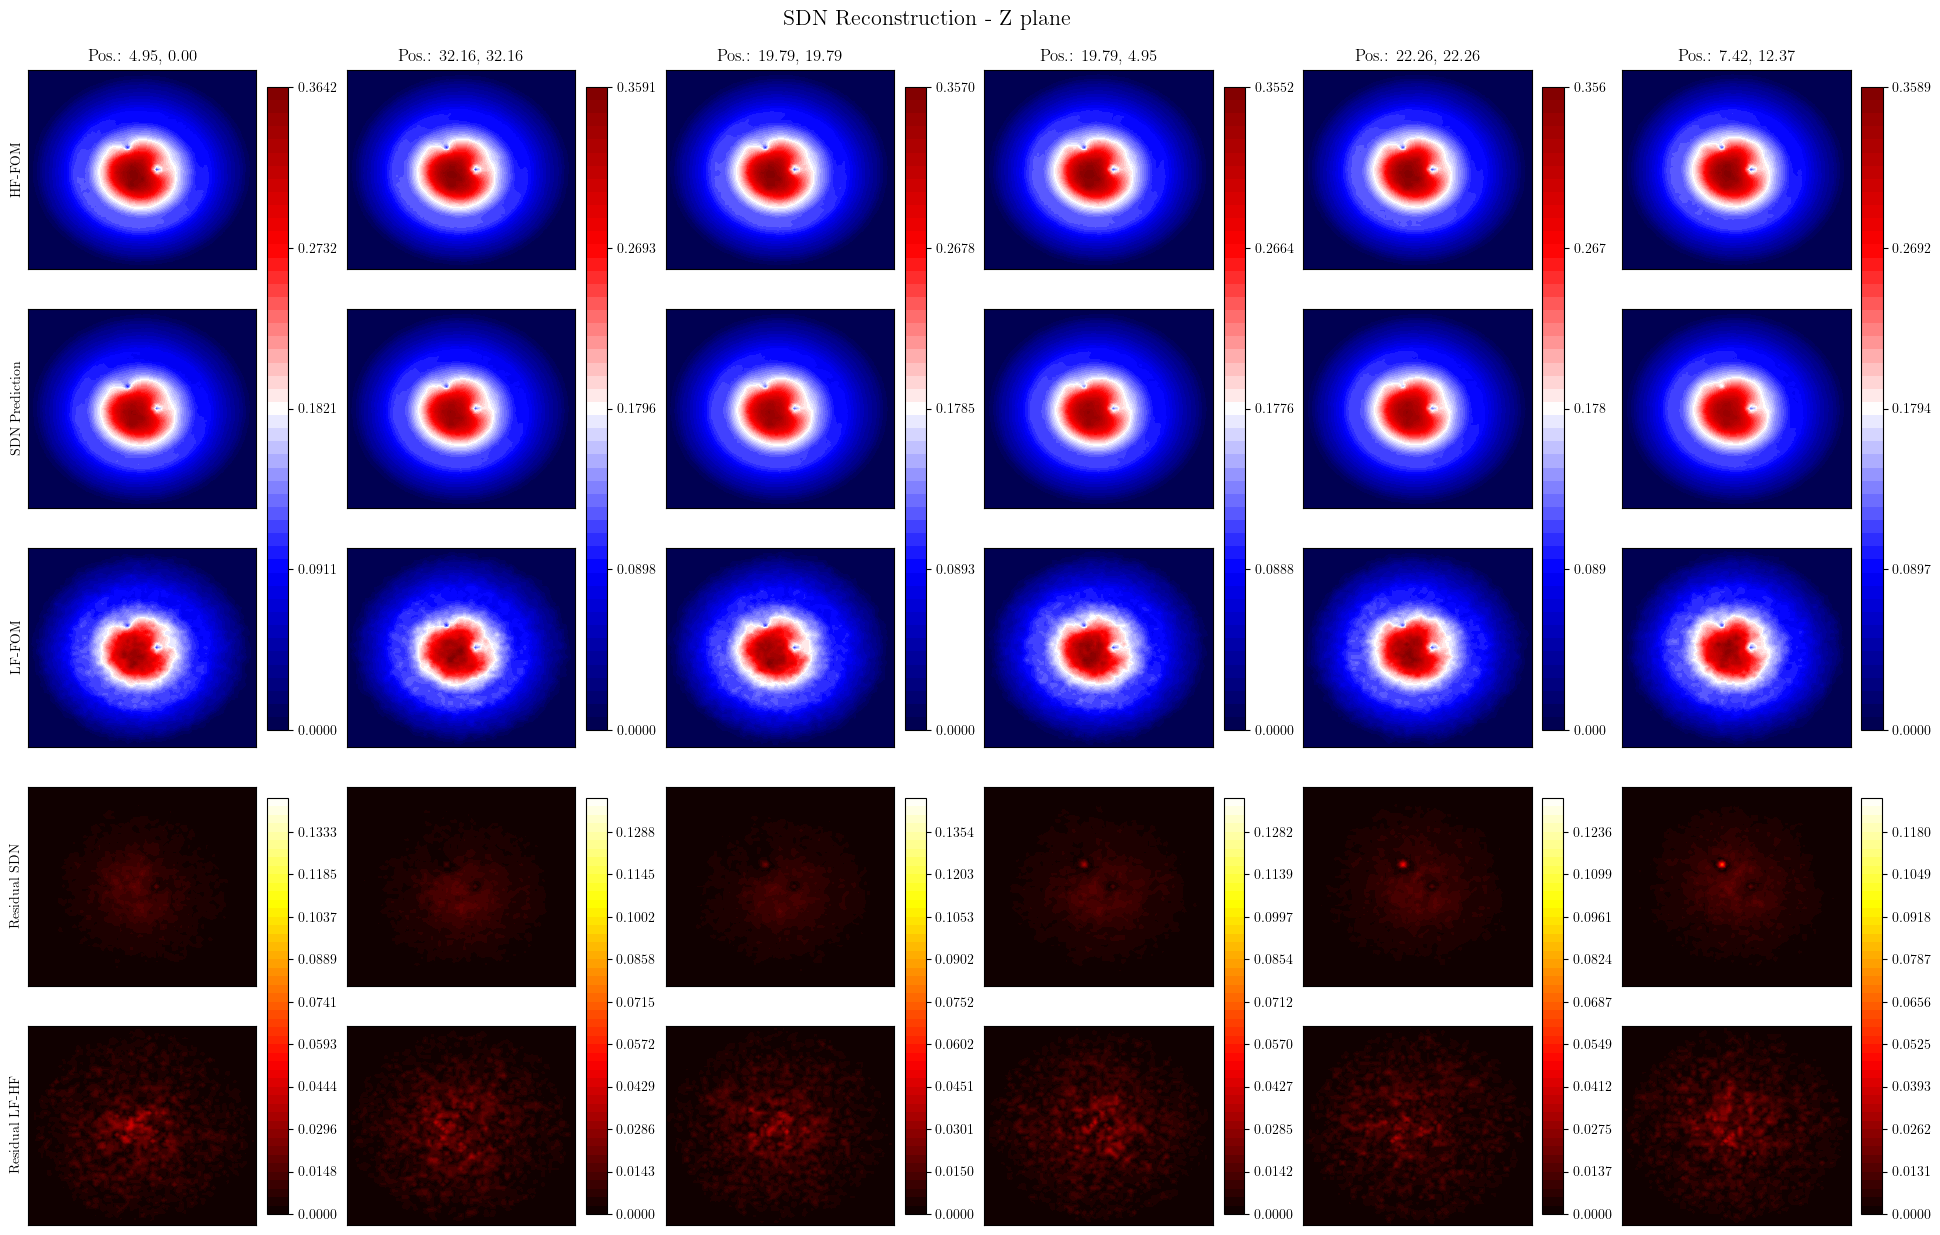

In [8]:
nrows = 5
ncols = 6

for normal in ['x', 'y', 'z']:

    fig, axs = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows))

    for ii in range(len(axs[0])):
        hf_fom = hf_snaps[:, ii] / lf_max_flux
        lf_fom = lf_snaps_comparison[:, ii] / lf_max_flux
        pred   = lf_sdn_pred[:, ii]

        _slice_fom = pl.get_slice(hf_fom, name='fom', plane_normal=normal)[1]

        levels = np.linspace(0, np.max(_slice_fom), 50)
        cont = pl.plot_slice(axs[0, ii], hf_fom, normal=normal, levels=levels, cmap=cmap)
        pl.plot_slice(axs[1, ii], pred, normal=normal, levels=levels, cmap=cmap)
        pl.plot_slice(axs[2, ii], lf_fom, normal=normal, levels=levels, cmap=cmap)

        # Residuals
        res_sdn = np.abs(hf_fom - pred)
        res_lfhf = np.abs(lf_fom - hf_fom)

        res_levels = np.linspace(0, max([res_sdn.max(), res_lfhf.max()]), len(levels))

        res_cont = pl.plot_slice(axs[3, ii], res_sdn, normal=normal, levels=res_levels, cmap=cmap_res)
        pl.plot_slice(axs[4, ii], res_lfhf, normal=normal, levels=res_levels, cmap=cmap_res)

        cbar = fig.colorbar(cont, ax=axs[:3,ii], orientation='vertical', fraction=0.1, pad=0.04, shrink=0.95, aspect=30)
        cbar.ax.set_yticks(np.linspace(0, levels.max(), 5))

        cbar_res = fig.colorbar(res_cont, ax=axs[3:,ii], orientation='vertical', fraction=0.1, pad=0.04, shrink=0.95, aspect=20)

        # Set titles 
        axs[0, ii].set_title('Pos.: {:.2f}, {:.2f}'.format(*lf_params[lf_test_indices[ii]]))

    for ax in axs.flatten():
        ax.set_xticks([])
        ax.set_yticks([])
        
    axs[0, 0].set_ylabel('HF-FOM')
    axs[1, 0].set_ylabel('SDN Prediction')
    axs[2, 0].set_ylabel('LF-FOM')
    axs[3, 0].set_ylabel('Residual SDN')
    axs[4, 0].set_ylabel('Residual LF-HF')
    fig.suptitle(f'SDN Reconstruction - {normal.upper()} plane', fontsize=16, y=0.92)

Let us make a plot of the relative error in the $l_2$-norm

/var/folders/wj/ljx542lx73z3721_ddn_zwtc0000gp/T/ipykernel_63916/728934992.py:1: RuntimeWarning: divide by zero encountered in matmul
  svd_recon = lf_modes @ (lf_modes.T @ (hf_snaps / lf_max_flux))
/var/folders/wj/ljx542lx73z3721_ddn_zwtc0000gp/T/ipykernel_63916/728934992.py:1: RuntimeWarning: overflow encountered in matmul
  svd_recon = lf_modes @ (lf_modes.T @ (hf_snaps / lf_max_flux))
/var/folders/wj/ljx542lx73z3721_ddn_zwtc0000gp/T/ipykernel_63916/728934992.py:1: RuntimeWarning: invalid value encountered in matmul
  svd_recon = lf_modes @ (lf_modes.T @ (hf_snaps / lf_max_flux))


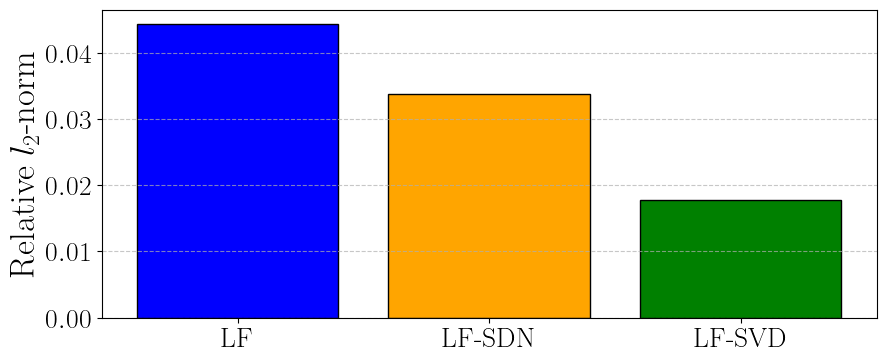

In [9]:
svd_recon = lf_modes @ (lf_modes.T @ (hf_snaps / lf_max_flux))

lf_norms = np.linalg.norm(hf_snaps/lf_max_flux - lf_snaps_comparison/lf_max_flux) / np.linalg.norm(hf_snaps/lf_max_flux)
lf_sdn_norms = np.linalg.norm(hf_snaps/lf_max_flux - lf_sdn_pred) / np.linalg.norm(hf_snaps/lf_max_flux)
lf_svd_norms = np.linalg.norm(hf_snaps/lf_max_flux - svd_recon) / np.linalg.norm(hf_snaps/lf_max_flux)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(['LF', 'LF-SDN', 'LF-SVD'], [lf_norms, lf_sdn_norms, lf_svd_norms], color=['blue', 'orange', 'green'], edgecolor='black')
ax.set_ylabel('Relative $l_2$-norm', fontsize=25)
ax.tick_params(labelsize=20)
ax.grid(axis='y', linestyle='--', alpha=0.7)

## Step 2: mapping the LF to the HF
The previous network allows to predict the state starting from LF measurements and parameters, i.e. $\hat{\mathbf{u}}_{LF} = \mathbb{U}_{LF}\mathbf{f}_{SDN}(\mathbf{y}_{LF}, \boldsymbol{\mu})$.
However, it has been observed from the previous figures that there is a discrepancy between the LF and HF solutions (related to noise) and some local discrepancy given by the CR position, let us define the residual field as
$$\boldsymbol{\delta}=\mathbf{u}_{HF} - \hat{\mathbf{u}}_{LF}$$
where $\mathbf{u}_{HF}$ is the HF solution.

We are going to define a shallow network $\mathbf{f}_{res}$ which take the CR position and the LF reduced coefficients as input and outputs the residual field $\boldsymbol{\delta}$, i.e.
$$\boldsymbol{\delta} \approx \mathbf{f}_{res}(\hat{\mathbf{v}}_{LF})$$
so that the state can be predicted as
$$\mathbf{u}_{HF} \approx \hat{\mathbf{u}}_{HF} = \hat{\mathbf{u}}_{LF} + \mathbf{f}_{res}(\hat{\mathbf{v}}_{LF})$$

Let us select the HF solution to use by adopting Latin-Hypercube sampling (LHS).

In [10]:
from scipy.stats import qmc
from scipy.spatial import cKDTree

hf_samples = 15
print(f'Number of used HF samples: {hf_samples} / {hf_snaps.shape[1]} total samples ({hf_samples / hf_snaps.shape[1] * 100:.2f}%)')

# Define LHS sampler in 2D
seedtest = 20  # Set a seed for reproducibility
sampler = qmc.LatinHypercube(d=2, seed=seedtest)

# Generate LHS points in the unit square
lhs_points = sampler.random(n=hf_samples)

# Scale the LHS points to the range of your data
min_vals = np.min(hf_params, axis=0)
max_vals = np.max(hf_params, axis=0)

# Scale LHS to data range
scaled_lhs_points = qmc.scale(lhs_points, min_vals, max_vals)

tree = cKDTree(hf_params)
distances, hf_indices = tree.query(scaled_lhs_points, k=1)
hf_indices = np.unique(hf_indices)

# Extract the corresponding HF data
hf_snaps_lhs  = hf_snaps[:, hf_indices] / lf_max_flux
hf_params_lhs = hf_params[hf_indices]
lf_snaps_lhs  = lf_snaps_comparison[:, hf_indices] / lf_max_flux

Number of used HF samples: 15 / 121 total samples (12.40%)


Let us plot the chosen parameters

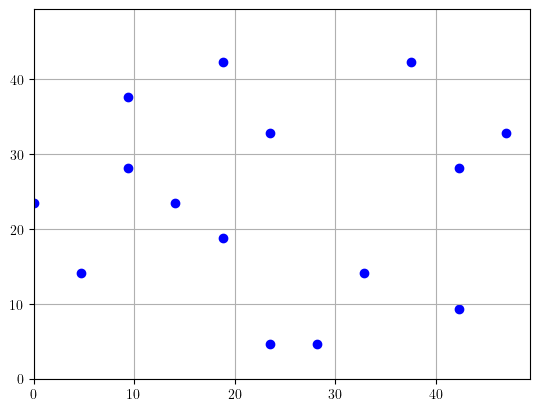

In [11]:
plt.scatter(hf_params_lhs[:, 0], hf_params_lhs[:, 1], c='blue', label='HF Samples')
plt.xlim(min_vals[0], max_vals[0]*1.05)
plt.ylim(min_vals[1], max_vals[1]*1.05)
plt.grid()

Let us define the train, test and validation sets for the residual network.

In [12]:
train_indices, test_indices = train_test_split(np.arange(len(hf_params_lhs)), test_size=0.2, random_state=42)
train_indices, valid_indices = train_test_split(train_indices, test_size=0.2, random_state=42)

print(train_indices.shape, test_indices.shape, valid_indices.shape)

(9,) (3,) (3,)


Let us define the input vectors for the residual network, i.e. the CR position and the LF reduced coefficients calculated with the SDN.

In [13]:
# _input = np.concatenate([lf_snaps_lhs[lf_idx_sens_locs], hf_params_lhs.T], axis=0)
_input = hf_params_lhs.T
_input = lf_input_scaler.transform(_input.T).T
_input = torch.tensor(_input, dtype=torch.float32).to(device).T

# Obtain the reduced coefficients predicted by the SDN
lf_sdn_red_coeff = lf_sdn.forward_pod(_input).cpu().detach().numpy() # shape (Nsample, rank)

train_input = lf_sdn_red_coeff[train_indices]
test_input  = lf_sdn_red_coeff[test_indices]
valid_input = lf_sdn_red_coeff[valid_indices]

# Define the scaler
hf_input_scaler = MinMaxScaler()
hf_input_scaler.fit(train_input)

train_input = hf_input_scaler.transform(train_input)
test_input  = hf_input_scaler.transform(test_input)
valid_input = hf_input_scaler.transform(valid_input)

Let us use the training HF solution to define a set of spatial weights for the loss function: in particular, let us compute the average residual field on each spatial point.

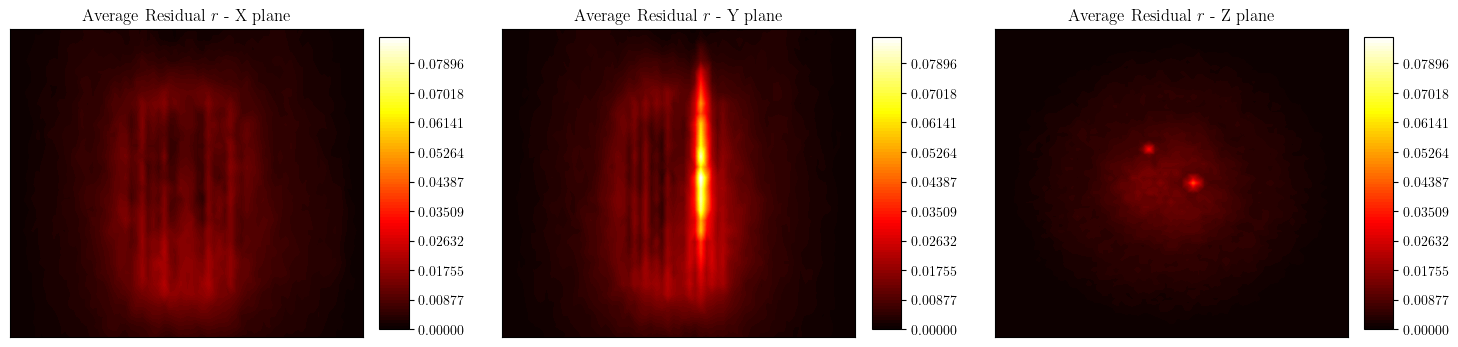

In [14]:
residuals = np.abs(hf_snaps_lhs[:, train_indices] - lf_sdn(_input)[train_indices].cpu().detach().numpy().T).mean(axis=1)

# Plot of the residual
fig, axs = plt.subplots(1,3, figsize=(18, 4))

levels = np.linspace(0, residuals.max(), 100)

for ii, normal in enumerate(['x', 'y', 'z']):
    cont = pl.plot_slice(axs[ii], residuals, normal=normal, cmap=cmap_res, levels=levels)
    fig.colorbar(cont, ax=axs[ii], orientation='vertical', fraction=0.1, pad=0.04, shrink=0.95, aspect=10)

    axs[ii].set_xticks([])
    axs[ii].set_yticks([])
    axs[ii].set_title(f'Average Residual $r$ - {normal.upper()} plane')

In this cell, we will define additional loss functions to make a sensitivity analysis of the residual network to find a good solution to reduce the local residual:

- Weighted L2 loss: each term of the sum is weighted by a function $w(x)$, based on the residual
- Max error loss: the loss is defined as the maximum error in the residual field

In [15]:
from torch import nn

class WeightedL2Loss(nn.Module):
    def __init__(self, weight_mask=None):
        """
        Args:
            weight_mask: 1D tensor of shape [N] with spatial weights (optional).
                         Should sum to 1 or be normalized beforehand.
        """
        super().__init__()

        self.weight_mask = weight_mask

    def forward(self, pred_delta, true_delta):
        """
        Args:
            pred_delta: Tensor of shape [batch_size, N]
            true_delta: Tensor of shape [batch_size, N]
        Returns:
            Weighted L2 loss (scalar)
        """
        if self.weight_mask is not None:
            loss = ((pred_delta - true_delta) ** 2) * self.weight_mask.unsqueeze(0)
        else:
            loss = (pred_delta - true_delta) ** 2

        return loss.mean()
    
weight_mask = torch.tensor(residual / residual.sum(), dtype=torch.float32).to(device)

from utils.sdn import num2p, mre
mse_reg_max = lambda datatrue, datapred: mre(datatrue, datapred) + 0.25 * torch.max(torch.abs(datatrue - datapred), axis=-1)[0].mean()

Let us define the dataset and the network.

In [16]:
import torch
from utils.mf_sdn import CorrectionDataset, ResidualSDNetwork

# Define the datasets

train_delta_dataset = CorrectionDataset(
    torch.tensor(train_input, dtype=torch.float32).to(device),
    lf_sdn(_input)[train_indices].detach().clone(), 
    torch.tensor(hf_snaps_lhs[:, train_indices].T, dtype=torch.float32).to(device)
)
test_delta_dataset = CorrectionDataset(
    torch.tensor(test_input, dtype=torch.float32).to(device),
    lf_sdn(_input)[test_indices].detach().clone(),
    torch.tensor(hf_snaps_lhs[:, test_indices].T, dtype=torch.float32).to(device)
)
valid_delta_dataset = CorrectionDataset(
    torch.tensor(valid_input, dtype=torch.float32).to(device),
    lf_sdn(_input)[valid_indices].detach().clone(),
    torch.tensor(hf_snaps_lhs[:, valid_indices].T, dtype=torch.float32).to(device)
)

# Define the Residual SDN
in_dim = train_input.shape[1]
out_dim = hf_snaps_lhs.shape[0]
residual_sdn = ResidualSDNetwork(in_dim=in_dim, out_dim=out_dim, dropout=0.1, decoder_sizes=[350, 400]).to(device)

Here the Residual SDN is trained.

Residual SDN training time: 12.73 s04 Validation Loss 8.2889e-04


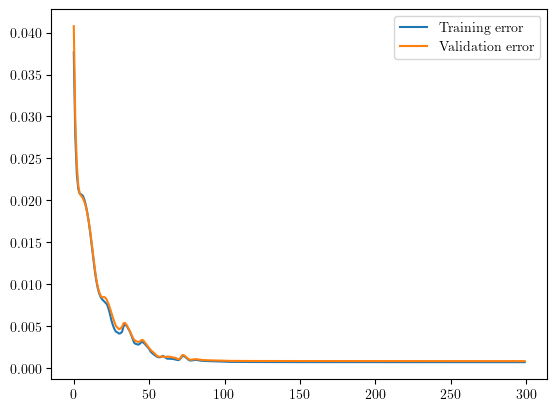

In [17]:
import time
from copy import deepcopy
from utils.mf_sdn import fit_res

loss_function = nn.L1Loss()

start = time.perf_counter()
train_res_errors, valid_res_errors = fit_res(
    model=residual_sdn,
    train_dataset=train_delta_dataset,
    valid_dataset=valid_delta_dataset,
    batch_size=32,
    epochs=300,
    patience=20,
    optim=torch.optim.Adam,
    criterion=loss_function,
    lr=0.001,
    verbose=True,
)
residual_sdn_train_time = time.perf_counter() - start
print(f'Residual SDN training time: {residual_sdn_train_time:.2f} s')

plt.plot(train_res_errors, label='Training error')
plt.plot(valid_res_errors, label='Validation error')
plt.legend()


### Tier B MF baselines
Classical correctors trained on the same HF subset as the residual SDN:
- **Linear-MF** on `v_LF` (LF POD coefficients),
- **GP-residual** on the POD residual,
- **Co-kriging** on HF POD modes vs. CR parameters $(\mu_1, \mu_2)$.


In [18]:
import time
import pandas as pd
from utils.mf_baselines import (
    LinearMFCorrector,
    PODGPRResidualCorrector,
    CoKrigingMFCorrector,
    evaluate_mf_methods,
)

mf_pod_rank = train_input.shape[1]

v_lf_train = train_delta_dataset.v_LF
u_lf_train = train_delta_dataset.u_LF
u_hf_train = train_delta_dataset.u_HF
mu_train = hf_params_lhs[train_indices]

start = time.perf_counter()
linear_mf = LinearMFCorrector(alpha=1e-6).fit(v_lf_train, u_lf_train, u_hf_train)
linear_fit_s = time.perf_counter() - start

start = time.perf_counter()
gp_residual = PODGPRResidualCorrector(rank=mf_pod_rank, alpha=1e-4).fit(v_lf_train, u_lf_train, u_hf_train)
gp_fit_s = time.perf_counter() - start

start = time.perf_counter()
cokriging_mf = CoKrigingMFCorrector(rank=mf_pod_rank, alpha=1e-4).fit(mu_train, u_lf_train, u_hf_train)
cokrig_fit_s = time.perf_counter() - start

mf_costs = pd.DataFrame(
    {
        'fit [s]': [linear_fit_s, gp_fit_s, cokrig_fit_s, residual_sdn_train_time],
        'index': ['Linear-MF', 'GP-residual', 'Co-kriging', 'SDN-MF'],
    }
).set_index('index')
display(mf_costs)


/opt/miniconda3/envs/ml/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/opt/miniconda3/envs/ml/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/opt/miniconda3/envs/ml/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/opt/miniconda3/envs/ml/lib/python3.10/site-packages/sklearn/linear_model/_base.py:314: RuntimeWarning: divide by zero encountered in matmul
  intercept_ = y_offset - X_offset @ coef_.T
/opt/miniconda3/envs/ml/lib/python3.10/site-packages/sklearn/linear_model/_base.py:314: RuntimeWarning: overflow encountered in matmul
  intercept_ = y_offset - X_offset @ coef_.T
/opt/miniconda3/envs/ml/lib/python3.10/site-packages/sklearn/linear_model/_base.py:314: RuntimeWarning: invalid value encountered in matmul
  intercept_ = y_offset - X_offset @ coef_.T
/opt/m

,fit [s]
index,
Linear-MF,0.021329
GP-residual,0.060763
Co-kriging,0.052187
SDN-MF,12.725320


Let us make a plot of the 

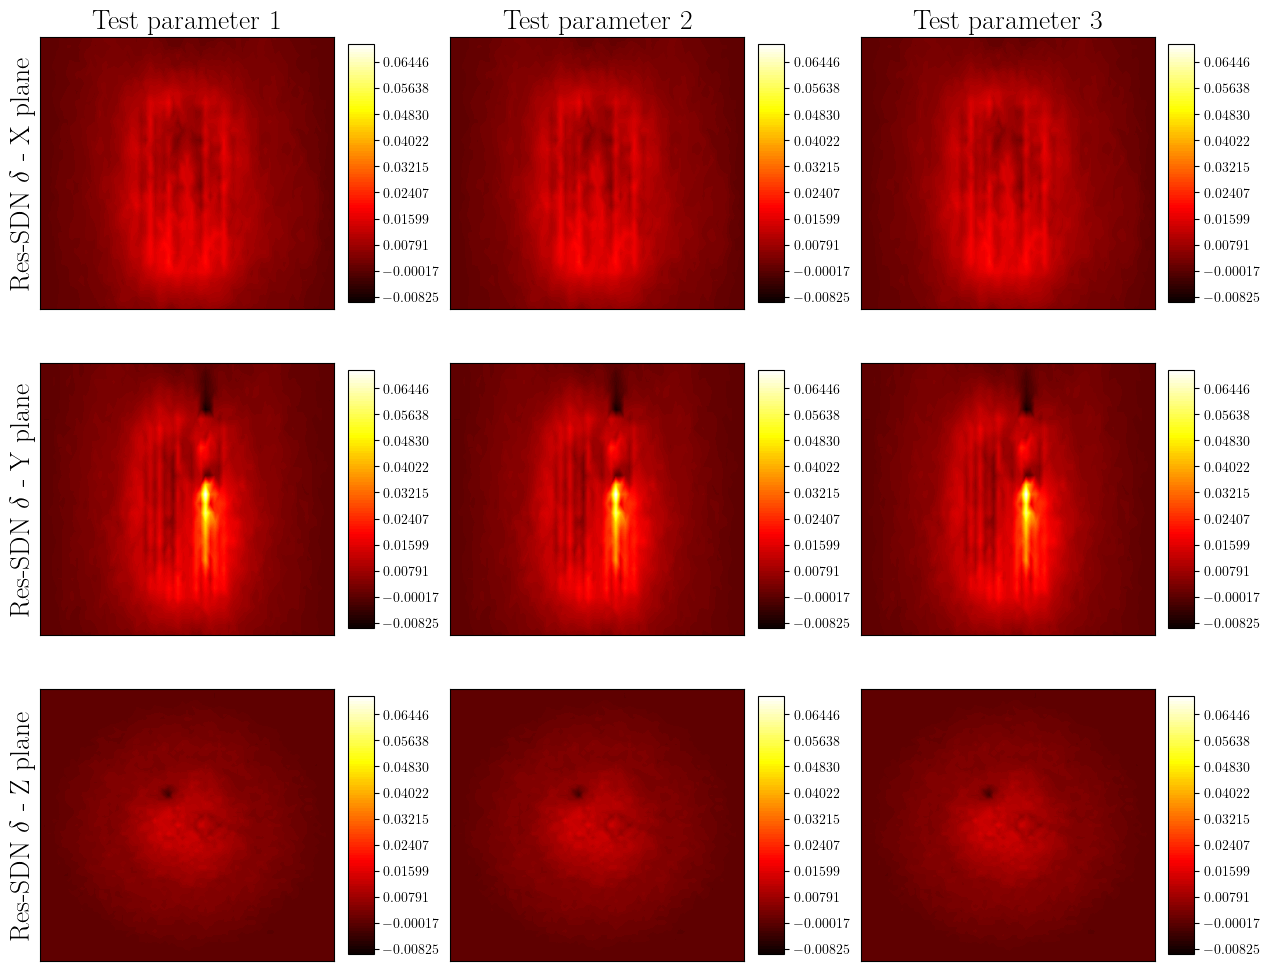

In [19]:
res_sdn_eval = residual_sdn(test_delta_dataset.v_LF).cpu().detach().numpy()
fig, axs = plt.subplots(3, res_sdn_eval.shape[0], figsize=(5 * res_sdn_eval.shape[0], 12))

levels = np.linspace(res_sdn_eval.min(), res_sdn_eval.max(), 100)

for jj in range(res_sdn_eval.shape[0]):
    for ii, normal in enumerate(['x', 'y', 'z']):
        cont = pl.plot_slice(axs[ii, jj], res_sdn_eval[jj], normal=normal, cmap=cm.hot, levels=levels)
        fig.colorbar(cont, ax=axs[ii, jj], orientation='vertical', fraction=0.1, pad=0.04, shrink=0.95, aspect=10)

        axs[ii, jj].set_xticks([])
        axs[ii, jj].set_yticks([])
        axs[ii, 0].set_ylabel(r'Res-SDN $\delta$ - '+f'{normal.upper()} plane', fontsize=20)

    axs[0, jj].set_title(f'Test parameter {jj+1}', fontsize=20)


Let us plot the errors.

In [20]:
pred_sdn_lf = test_delta_dataset.u_LF.cpu().numpy().T
pred_sdn_mf = (residual_sdn(test_delta_dataset.v_LF) + test_delta_dataset.u_LF).cpu().detach().numpy().T
pred_linear_mf = linear_mf.predict(test_delta_dataset.v_LF, test_delta_dataset.u_LF).T
pred_gp_mf = gp_residual.predict(test_delta_dataset.v_LF, test_delta_dataset.u_LF).T
pred_ck_mf = cokriging_mf.predict(hf_params_lhs[test_indices], test_delta_dataset.u_LF).T

test_lf_fom = lf_snaps_lhs[:, test_indices]
test_hf_fom = test_delta_dataset.u_HF.cpu().numpy().T
test_svd = lf_modes @ (lf_modes.T @ test_hf_fom)

mf_test_metrics = evaluate_mf_methods(
    test_hf_fom,
    {
        'Linear-MF': pred_linear_mf,
        'GP-residual': pred_gp_mf,
        'Co-kriging': pred_ck_mf,
        'SDN-MF': pred_sdn_mf,
        'SDN-LF': pred_sdn_lf,
        'SVD': test_svd,
    },
    reference_lf=test_lf_fom,
)
pd.DataFrame({k: {'rel-L2': v['l2'], 'rel-max': v['max']} for k, v in mf_test_metrics.items()}).T


/opt/miniconda3/envs/ml/lib/python3.10/site-packages/sklearn/linear_model/_base.py:282: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_.T + self.intercept_
/opt/miniconda3/envs/ml/lib/python3.10/site-packages/sklearn/linear_model/_base.py:282: RuntimeWarning: overflow encountered in matmul
  return X @ coef_.T + self.intercept_
/opt/miniconda3/envs/ml/lib/python3.10/site-packages/sklearn/linear_model/_base.py:282: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_.T + self.intercept_
/Users/rivas/Github/SDN4Neutronics/utils/mf_baselines.py:122: RuntimeWarning: divide by zero encountered in matmul
  delta = delta_pod @ self.modes.T
/Users/rivas/Github/SDN4Neutronics/utils/mf_baselines.py:122: RuntimeWarning: overflow encountered in matmul
  delta = delta_pod @ self.modes.T
/Users/rivas/Github/SDN4Neutronics/utils/mf_baselines.py:122: RuntimeWarning: invalid value encountered in matmul
  delta = delta_pod @ self.modes.T
/Users/rivas/Github/SDN4

,rel-L2,rel-max
LF,0.044840,0.074654
Linear-MF,0.039835,0.441765
GP-residual,0.018120,0.166265
Co-kriging,0.036258,0.397127
SDN-MF,0.016943,0.157391
SDN-LF,0.033910,0.138992
SVD,0.017857,0.132353


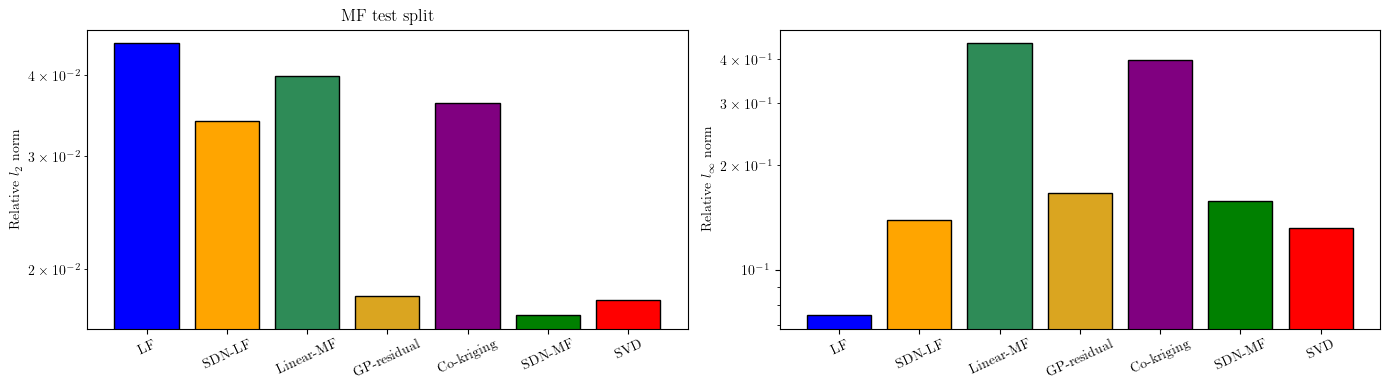

In [21]:
methods_mf_test = ['LF', 'SDN-LF', 'Linear-MF', 'GP-residual', 'Co-kriging', 'SDN-MF', 'SVD']
colors_mf = ['blue', 'orange', 'seagreen', 'goldenrod', 'purple', 'green', 'red']
l2_vals = [mf_test_metrics[m]['l2'] for m in methods_mf_test]
max_vals = [mf_test_metrics[m]['max'] for m in methods_mf_test]

fig, axs = plt.subplots(1, 2, figsize=(14, 4))
axs[0].bar(methods_mf_test, l2_vals, color=colors_mf, edgecolor='black')
axs[0].set_ylabel(r'Relative $l_2$ norm')
axs[0].set_yscale('log')
axs[0].set_title('MF test split')
axs[0].tick_params(axis='x', rotation=25)

axs[1].bar(methods_mf_test, max_vals, color=colors_mf, edgecolor='black')
axs[1].set_ylabel(r'Relative $l_\infty$ norm')
axs[1].set_yscale('log')
axs[1].tick_params(axis='x', rotation=25)
plt.tight_layout()
fig.savefig(os.path.join(path_res, 'mf_baselines_comparison_testsplit.pdf'), dpi=300, bbox_inches='tight')
plt.show()


### Assessment of the mapping accuracy on the whole HF dataset
Let us compare the models with respect to the full test HF dataset (121-15 MC simulations).

In [22]:
hf_test_full = np.setdiff1d(np.arange(len(hf_params)), hf_indices)

_input = hf_params[hf_test_full].T
_input = lf_input_scaler.transform(_input.T).T
_input = torch.tensor(_input, dtype=torch.float32).to(device).T

pred_sdn_lf = lf_sdn(_input).cpu().detach().numpy().T

_svd_coeff_lf_raw = lf_sdn.forward_pod(_input).cpu().detach().numpy()
_svd_coeff_lf = torch.tensor(hf_input_scaler.transform(_svd_coeff_lf_raw), dtype=torch.float32).to(device)
pred_sdn_mf = residual_sdn(_svd_coeff_lf).cpu().detach().numpy().T + pred_sdn_lf

u_lf_full = pred_sdn_lf.T
v_lf_full = hf_input_scaler.transform(_svd_coeff_lf_raw)
pred_linear_mf = linear_mf.predict(v_lf_full, u_lf_full).T
pred_gp_mf = gp_residual.predict(v_lf_full, u_lf_full).T
pred_ck_mf = cokriging_mf.predict(hf_params[hf_test_full], u_lf_full).T

lf_fom = lf_snaps_comparison[:, hf_test_full] / lf_max_flux
hf_fom = hf_snaps[:, hf_test_full] / lf_max_flux
svd_rec = lf_modes @ (lf_modes.T @ hf_fom)

mf_full_metrics = evaluate_mf_methods(
    hf_fom,
    {
        'Linear-MF': pred_linear_mf,
        'GP-residual': pred_gp_mf,
        'Co-kriging': pred_ck_mf,
        'SDN-MF': pred_sdn_mf,
        'SDN-LF': pred_sdn_lf,
        'SVD': svd_rec,
    },
    reference_lf=lf_fom,
)

mf_full_summary = pd.DataFrame({
    'rel-L2 mean': [mf_full_metrics[m]['l2'] for m in ['LF', 'SDN-LF', 'Linear-MF', 'GP-residual', 'Co-kriging', 'SDN-MF', 'SVD']],
    'rel-L2 std': [np.std(mf_full_metrics[m]['l2_per_sample']) for m in ['LF', 'SDN-LF', 'Linear-MF', 'GP-residual', 'Co-kriging', 'SDN-MF', 'SVD']],
    'rel-max mean': [mf_full_metrics[m]['max'] for m in ['LF', 'SDN-LF', 'Linear-MF', 'GP-residual', 'Co-kriging', 'SDN-MF', 'SVD']],
}).set_index(pd.Index(['LF', 'SDN-LF', 'Linear-MF', 'GP-residual', 'Co-kriging', 'SDN-MF', 'SVD']))
display(mf_full_summary)
print(f'Held-out test set size: {hf_fom.shape[1]} snapshots')


/opt/miniconda3/envs/ml/lib/python3.10/site-packages/sklearn/linear_model/_base.py:282: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_.T + self.intercept_
/opt/miniconda3/envs/ml/lib/python3.10/site-packages/sklearn/linear_model/_base.py:282: RuntimeWarning: overflow encountered in matmul
  return X @ coef_.T + self.intercept_
/opt/miniconda3/envs/ml/lib/python3.10/site-packages/sklearn/linear_model/_base.py:282: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_.T + self.intercept_
/Users/rivas/Github/SDN4Neutronics/utils/mf_baselines.py:122: RuntimeWarning: divide by zero encountered in matmul
  delta = delta_pod @ self.modes.T
/Users/rivas/Github/SDN4Neutronics/utils/mf_baselines.py:122: RuntimeWarning: overflow encountered in matmul
  delta = delta_pod @ self.modes.T
/Users/rivas/Github/SDN4Neutronics/utils/mf_baselines.py:122: RuntimeWarning: invalid value encountered in matmul
  delta = delta_pod @ self.modes.T
/Users/rivas/Github/SDN4

,rel-L2 mean,rel-L2 std,rel-max mean
LF,0.044306,0.000750,0.072433
SDN-LF,0.033650,0.002111,0.153924
Linear-MF,0.022886,0.013329,0.261372
GP-residual,0.015168,0.003457,0.166518
Co-kriging,0.020996,0.012296,0.229593
SDN-MF,0.016994,0.002973,0.183832
SVD,0.017783,0.001580,0.137714


Held-out test set size: 106 snapshots


/Users/rivas/Github/SDN4Neutronics/utils/mf_baselines.py:122: RuntimeWarning: divide by zero encountered in matmul
  delta = delta_pod @ self.modes.T
/Users/rivas/Github/SDN4Neutronics/utils/mf_baselines.py:122: RuntimeWarning: overflow encountered in matmul
  delta = delta_pod @ self.modes.T
/Users/rivas/Github/SDN4Neutronics/utils/mf_baselines.py:122: RuntimeWarning: invalid value encountered in matmul
  delta = delta_pod @ self.modes.T
/Users/rivas/Github/SDN4Neutronics/utils/mf_baselines.py:122: RuntimeWarning: divide by zero encountered in matmul
  delta = delta_pod @ self.modes.T
/Users/rivas/Github/SDN4Neutronics/utils/mf_baselines.py:122: RuntimeWarning: overflow encountered in matmul
  delta = delta_pod @ self.modes.T
/Users/rivas/Github/SDN4Neutronics/utils/mf_baselines.py:122: RuntimeWarning: invalid value encountered in matmul
  delta = delta_pod @ self.modes.T
/Users/rivas/Github/SDN4Neutronics/utils/mf_baselines.py:122: RuntimeWarning: divide by zero encountered in matmul

,fit [s],predict [s]
index,,
Linear-MF,0.021329,NaN
GP-residual,0.060763,0.021694
Co-kriging,0.052187,NaN
SDN-MF,12.725320,0.016445


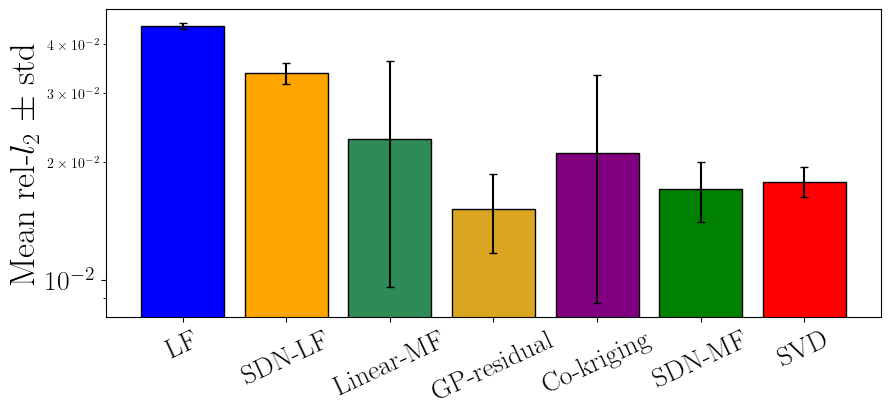

In [25]:
methods_full = ['LF', 'SDN-LF', 'Linear-MF', 'GP-residual', 'Co-kriging', 'SDN-MF', 'SVD']
colors_full = ['blue', 'orange', 'seagreen', 'goldenrod', 'purple', 'green', 'red']

fig, axs = plt.subplots(1, 1, figsize=(10, 4))
means_l2 = [mf_full_summary.loc[m, 'rel-L2 mean'] for m in methods_full]
stds_l2 = [mf_full_summary.loc[m, 'rel-L2 std'] for m in methods_full]
means_max = [mf_full_summary.loc[m, 'rel-max mean'] for m in methods_full]

axs.bar(methods_full, means_l2, yerr=stds_l2, color=colors_full, edgecolor='black', capsize=3)
axs.set_ylabel(r'Mean rel-$l_2$ $\pm$ std', fontsize=25)
axs.set_yscale('log')
axs.tick_params(axis='x', rotation=25, labelsize=20)
axs.tick_params(axis='y', labelsize=20)


fig.savefig(os.path.join(path_res, 'immy_mf_l2_norms_comparison_fulldataset_lf_mf.pdf'), dpi=300, bbox_inches='tight')

start = time.perf_counter()
for _ in range(10):
    _ = gp_residual.predict(v_lf_full, u_lf_full)
gp_predict_s = (time.perf_counter() - start) / 10
start = time.perf_counter()
for _ in range(10):
    _ = residual_sdn(_svd_coeff_lf).cpu().detach().numpy().T + pred_sdn_lf
sdn_predict_s = (time.perf_counter() - start) / 10
mf_costs['predict [s]'] = [np.nan, gp_predict_s, np.nan, sdn_predict_s]
display(mf_costs)


Let us compute the l2 error for each test simulation and plot the results.

In [26]:
sdn_lf_l2_norms = np.linalg.norm(hf_fom - pred_sdn_lf, axis=0) / np.linalg.norm(hf_fom, axis=0)
sdn_mf_l2_norms = np.linalg.norm(hf_fom - pred_sdn_mf, axis=0) / np.linalg.norm(hf_fom, axis=0)
gp_l2_norms = np.linalg.norm(hf_fom - pred_gp_mf, axis=0) / np.linalg.norm(hf_fom, axis=0)
ck_l2_norms = np.linalg.norm(hf_fom - pred_ck_mf, axis=0) / np.linalg.norm(hf_fom, axis=0)
lf_l2_norms = np.linalg.norm(hf_fom - lf_fom, axis=0) / np.linalg.norm(hf_fom, axis=0)
svd_l2_norms = np.linalg.norm(hf_fom - svd_rec, axis=0) / np.linalg.norm(hf_fom, axis=0)

# fig, axs = plt.subplots(6, 1, figsize=(10, 22), sharex=True, sharey=True)
# series = [
#     ('LF', lf_l2_norms, 'blue'),
#     ('SDN-LF', sdn_lf_l2_norms, 'orange'),
#     ('GP-residual', gp_l2_norms, 'goldenrod'),
#     ('Co-kriging', ck_l2_norms, 'purple'),
#     ('SDN-MF', sdn_mf_l2_norms, 'green'),
#     ('SVD', svd_l2_norms, 'red'),
# ]
# for ax, (label, vals, color) in zip(axs, series):
#     ax.bar(np.arange(hf_fom.shape[1]), vals, color=color, edgecolor='black')
#     ax.set_ylabel(f'rel-$l_2$ {label}', fontsize=16)
# plt.tight_layout()
# fig.savefig(os.path.join(path_res, 'per_snapshot_l2_all_methods.pdf'), dpi=300, bbox_inches='tight')
# plt.show()


In [27]:
best_err_mf = np.argmin(sdn_mf_l2_norms)
second_best_err_mf = np.argmin(np.delete(sdn_mf_l2_norms, best_err_mf))
worst_err_mf = np.argmax(sdn_mf_l2_norms)

print('Best MF SDN index:', best_err_mf)
print('Second Best MF SDN index:', second_best_err_mf)
print('Worst MF SDN index:', worst_err_mf)

test_idx_to_plot = [best_err_mf, second_best_err_mf, worst_err_mf]

Best MF SDN index: 64
Second Best MF SDN index: 84
Worst MF SDN index: 95


Contour plots

<>:50: SyntaxWarning: invalid escape sequence '\m'
<>:50: SyntaxWarning: invalid escape sequence '\m'
/var/folders/wj/ljx542lx73z3721_ddn_zwtc0000gp/T/ipykernel_75087/1945183838.py:50: SyntaxWarning: invalid escape sequence '\m'
  fig.suptitle(f'SDN Reconstruction - $\mathbf{{e}}_{{{normal}}}$ normal', fontsize=30, y=0.92)


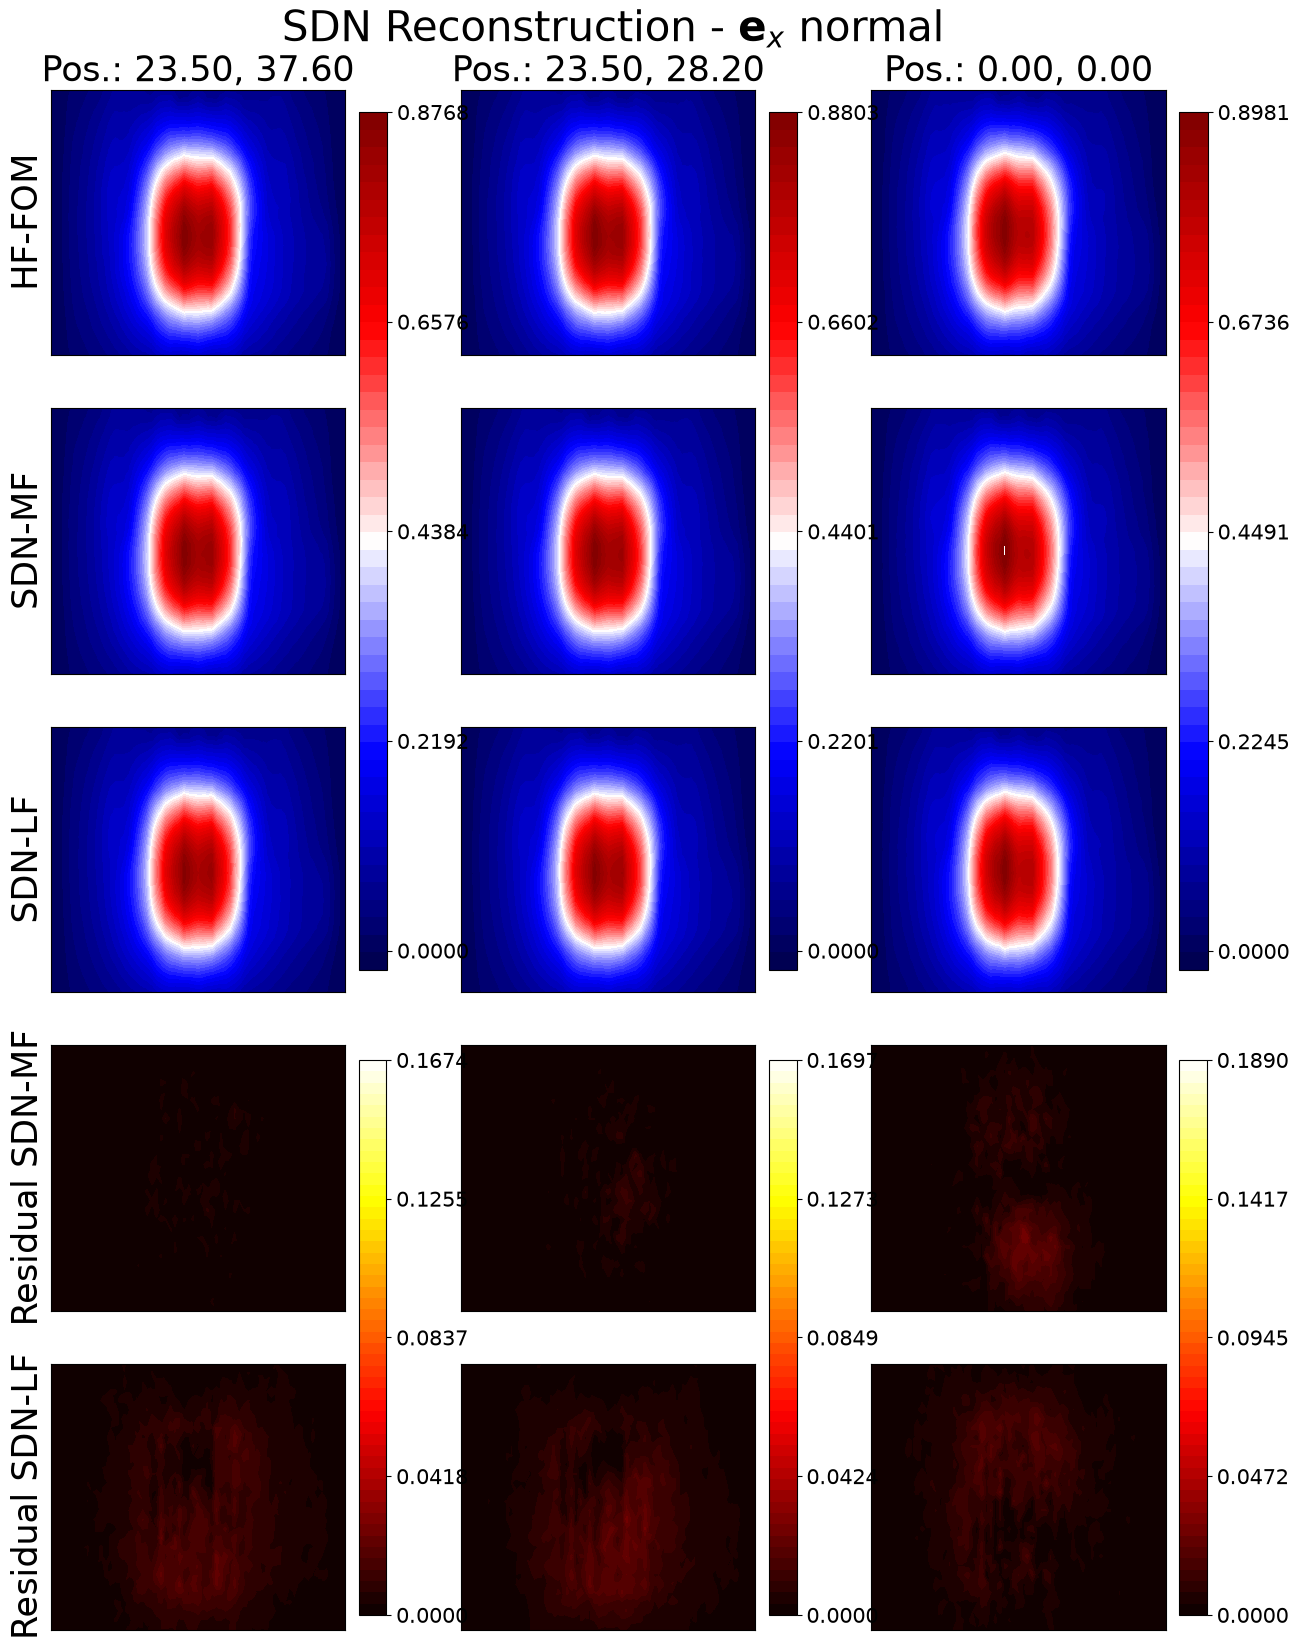

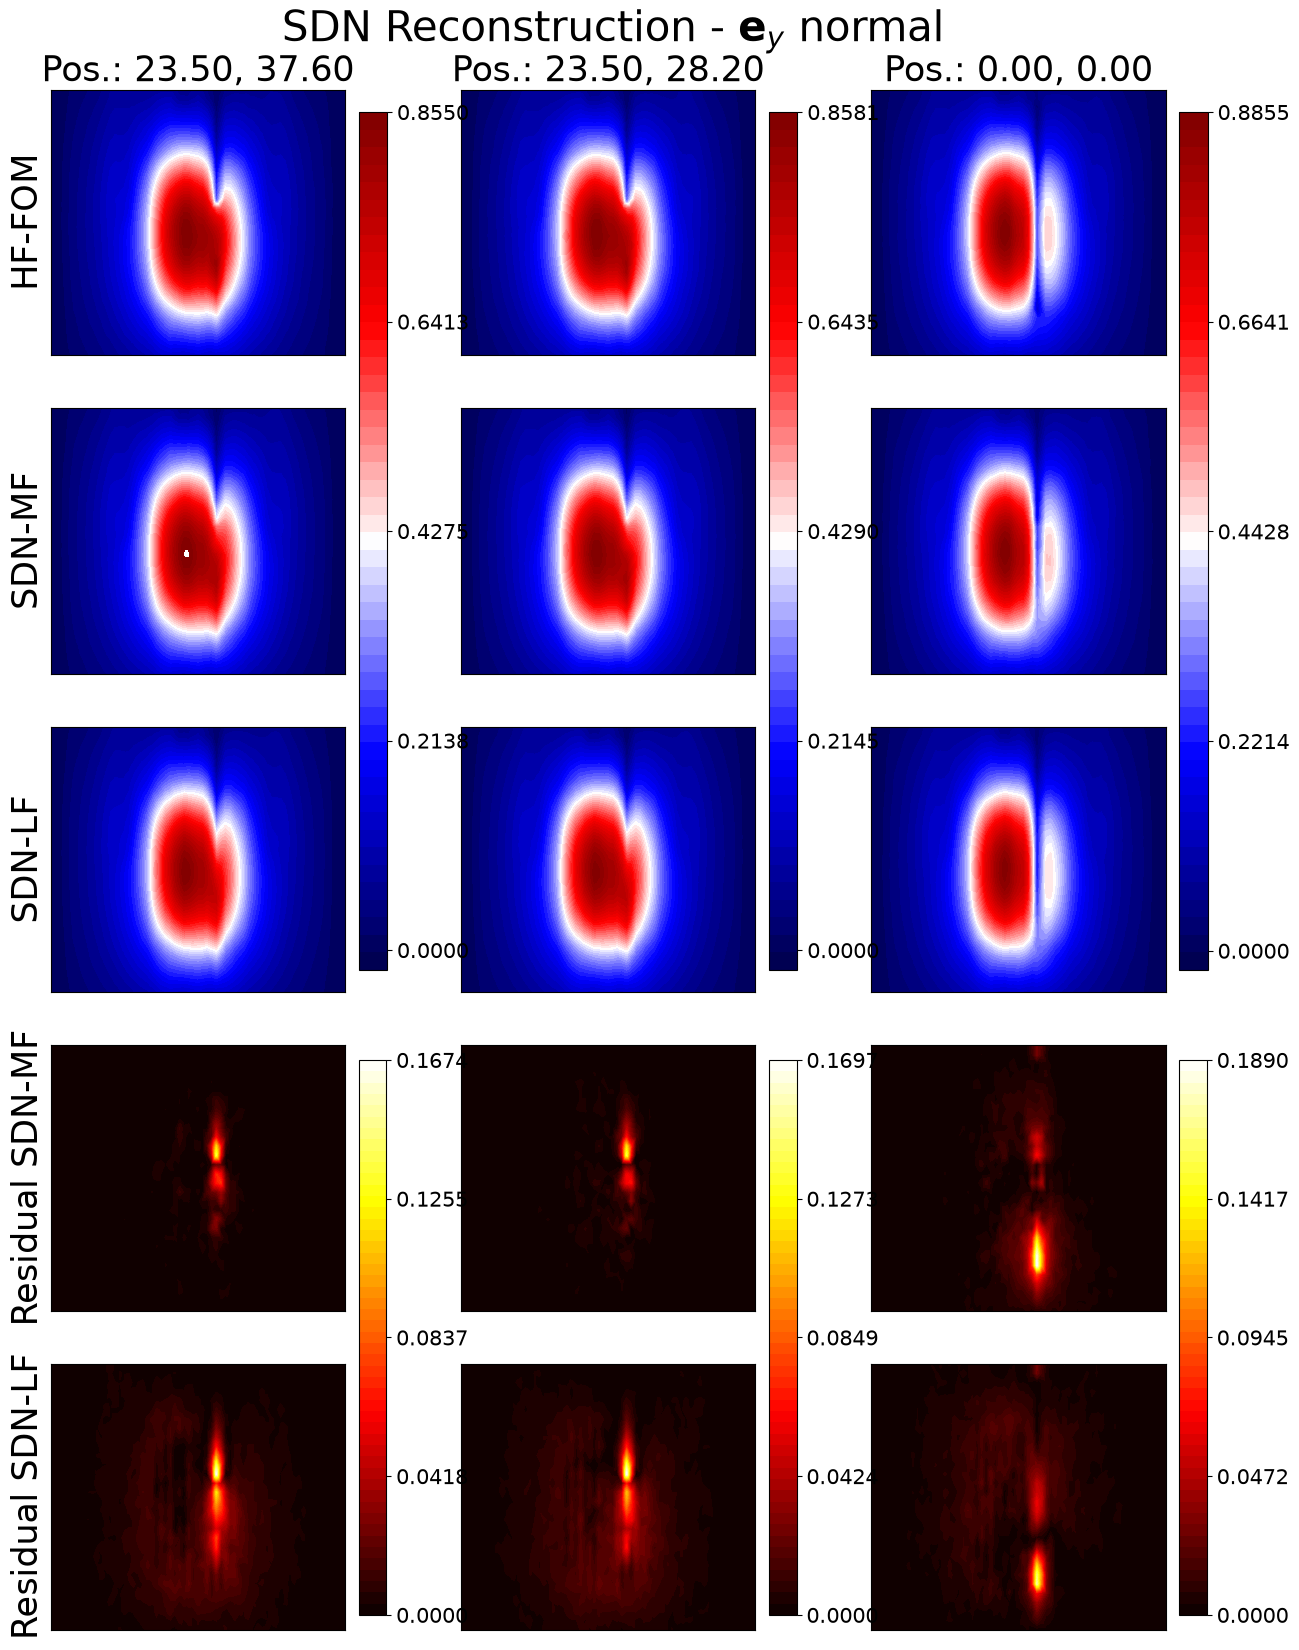

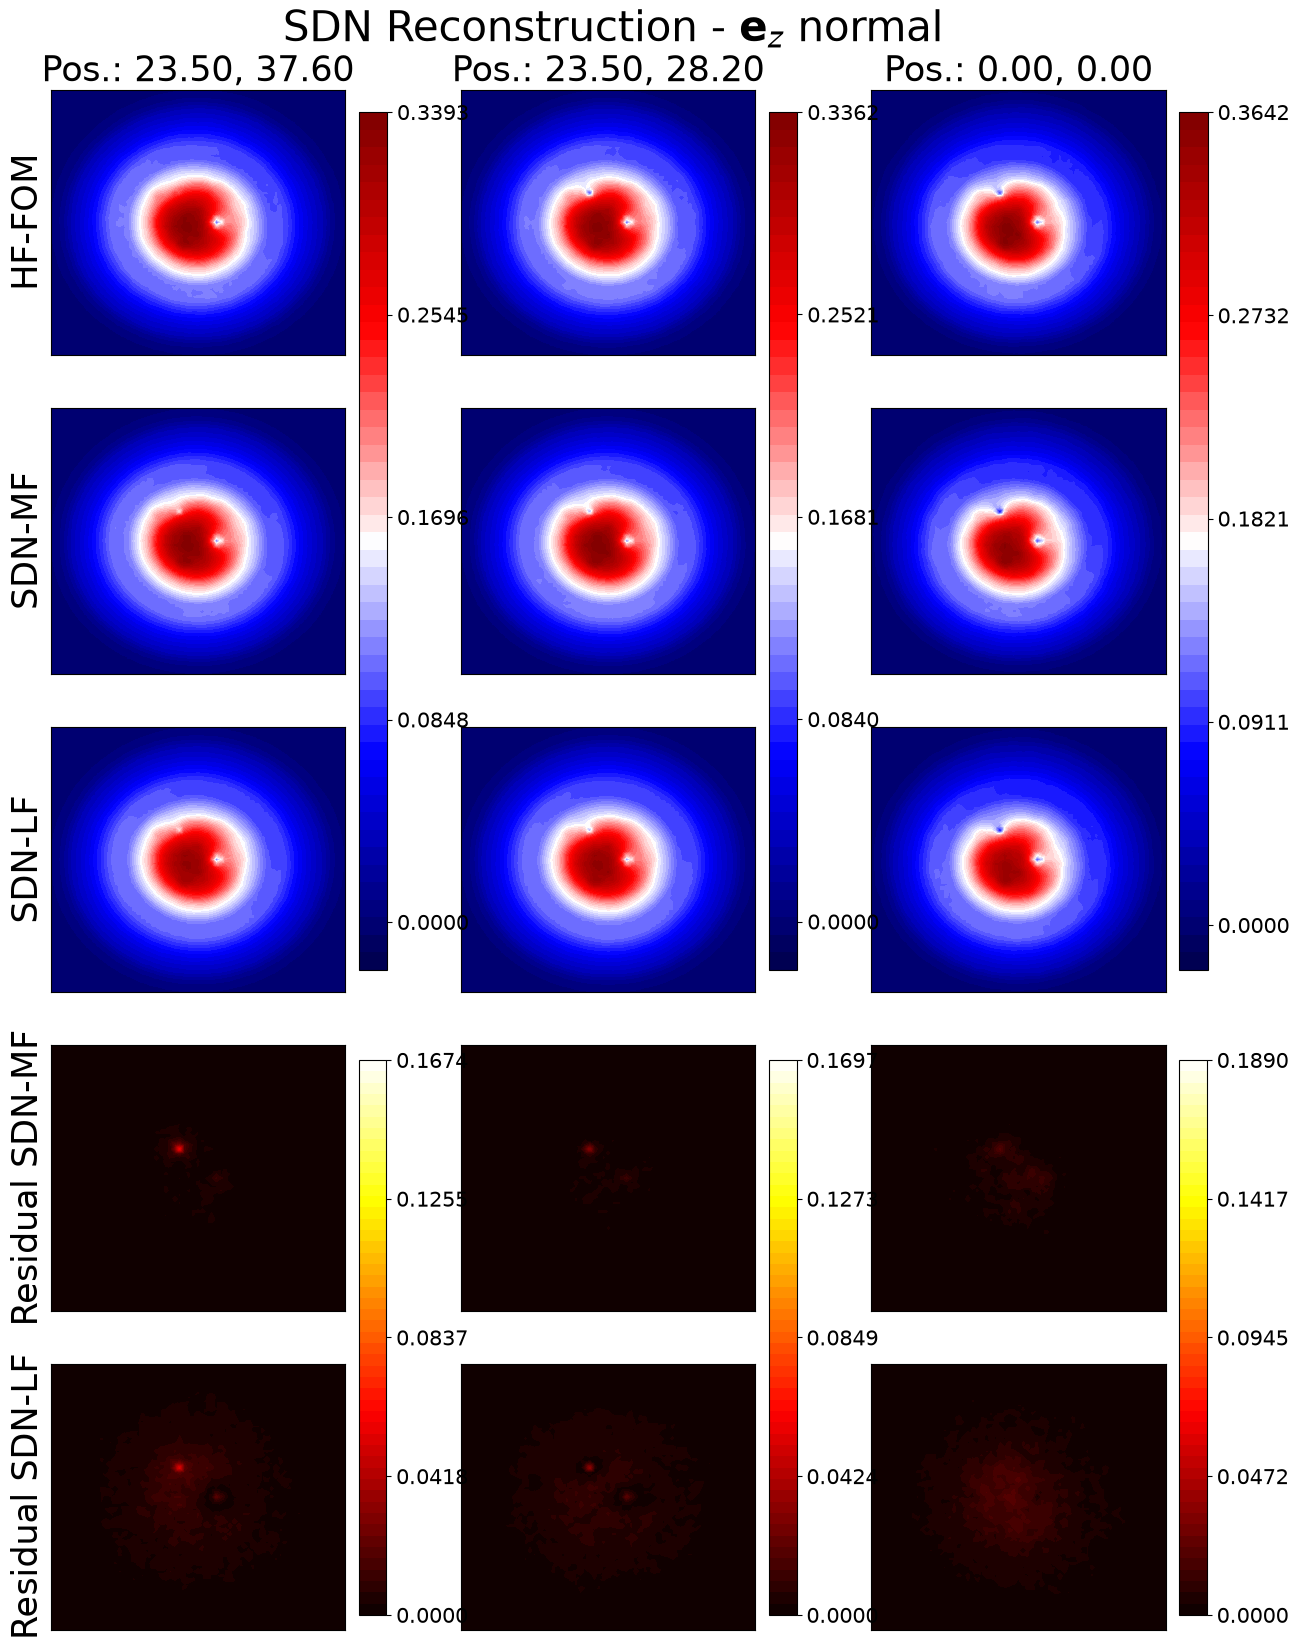

In [27]:
nrows = 5
ncols = len(test_idx_to_plot) # test_hf_fom.shape[1]

for normal in ['x', 'y', 'z']:

    fig, axs = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))

    for ii in range(len(axs[0])):
        hf_fom_plot   = hf_fom[:, test_idx_to_plot[ii]]
        sdn_lf   = pred_sdn_lf[:, test_idx_to_plot[ii]]
        sdn_mf   = pred_sdn_mf[:, test_idx_to_plot[ii]]

        _slice_fom = pl.get_slice(hf_fom_plot, name='fom', plane_normal=normal)[1]
        
        levels = np.linspace(-0.02, np.max(_slice_fom), 50)
        cont = pl.plot_slice(axs[0, ii], hf_fom_plot, normal=normal, levels=levels, cmap=cmap)
        pl.plot_slice(axs[1, ii], sdn_mf, normal=normal, levels=levels, cmap=cmap)
        pl.plot_slice(axs[2, ii], sdn_lf, normal=normal, levels=levels, cmap=cmap)

        # Residuals
        res_sdn_mf = np.abs(hf_fom_plot - sdn_mf)
        res_sdn_lf = np.abs(hf_fom_plot - sdn_lf)

        res_levels = np.linspace(0, max([res_sdn_lf.max(), res_sdn_mf.max()]), len(levels))

        res_cont = pl.plot_slice(axs[3, ii], res_sdn_mf, normal=normal, levels=res_levels, cmap=cmap_res)
        pl.plot_slice(axs[4, ii], res_sdn_lf, normal=normal, levels=res_levels, cmap=cmap_res)

        cbar = fig.colorbar(cont, ax=axs[:3,ii], orientation='vertical', fraction=0.1, pad=0.04, shrink=0.95, aspect=30)
        cbar.ax.set_yticks(np.linspace(0, levels.max(), 5))
        cbar.ax.tick_params(labelsize=15)

        cbar_res = fig.colorbar(res_cont, ax=axs[3:,ii], orientation='vertical', fraction=0.1, pad=0.04, shrink=0.95, aspect=20)
        cbar_res.ax.set_yticks(np.linspace(0, res_levels.max(), 5))
        cbar_res.ax.tick_params(labelsize=15)


        # Set titles 
        axs[0, ii].set_title('Pos.: {:.2f}, {:.2f}'.format(*hf_params[hf_test_full[test_idx_to_plot[ii]]]), fontsize=25)

    for ax in axs.flatten():
        ax.set_xticks([])
        ax.set_yticks([])
        
    axs[0, 0].set_ylabel('HF-FOM', fontsize=25)
    axs[1, 0].set_ylabel('SDN-MF', fontsize=25)
    axs[2, 0].set_ylabel('SDN-LF', fontsize=25)
    axs[3, 0].set_ylabel('Residual SDN-MF', fontsize=25)
    axs[4, 0].set_ylabel('Residual SDN-LF', fontsize=25)
    fig.suptitle(f'SDN Reconstruction - $\mathbf{{e}}_{{{normal}}}$ normal', fontsize=30, y=0.92)
    fig.savefig(os.path.join(path_res, f'mf_sdn_reconstruction_testset_{normal}.png'), dpi=300, bbox_inches='tight')

Let us make a histogram of the distribution of the errors for the different methods over space.

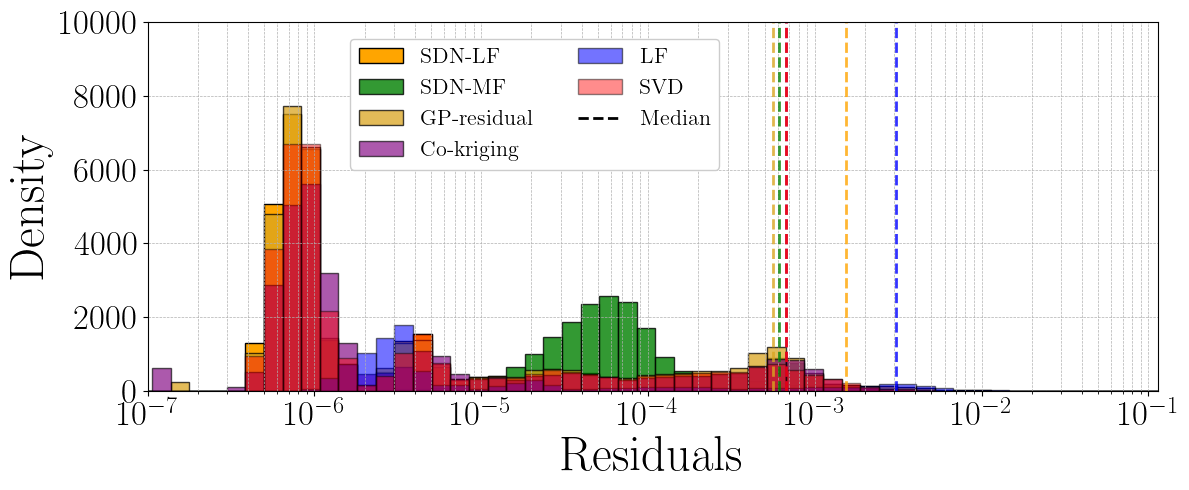

In [40]:
residual_field_sdn_lf = np.abs(hf_fom - pred_sdn_lf).mean(axis=-1)
residual_field_sdn_mf = np.abs(hf_fom - pred_sdn_mf).mean(axis=-1)
residual_field_gp = np.abs(hf_fom - pred_gp_mf).mean(axis=-1)
residual_field_ck = np.abs(hf_fom - pred_ck_mf).mean(axis=-1)
residual_field_lf = np.abs(hf_fom - lf_fom).mean(axis=-1)
residual_field_svd = np.abs(hf_fom - svd_rec).mean(axis=-1)

fig, axs = plt.subplots(1, 1, figsize=(12,5))
nbins = 100
all_res = [residual_field_sdn_lf, residual_field_sdn_mf, residual_field_gp, residual_field_ck, residual_field_lf, residual_field_svd]
data_max = max(v.max() for v in all_res)
bins = np.logspace(-12, np.log10(data_max), nbins)

plot_specs = [
    ('SDN-LF', residual_field_sdn_lf, 'orange', 1.0),
    ('SDN-MF', residual_field_sdn_mf, 'green', 0.8),
    ('GP-residual', residual_field_gp, 'goldenrod', 0.75),
    ('Co-kriging', residual_field_ck, 'purple', 0.65),
    ('LF', residual_field_lf, 'blue', 0.55),
    ('SVD', residual_field_svd, 'red', 0.45),
]
for label, data, color, alpha in plot_specs:
    axs.hist(data, bins=bins, color=color, alpha=alpha, label=label, density=True, edgecolor='black')
    axs.axvline(np.median(data), color=color, linestyle='--', linewidth=2, alpha=0.8)

axs.set_xscale('log')
axs.set_ylim(0, 1e4)
axs.set_xlabel('Residuals', fontsize=35)
axs.set_ylabel('Density', fontsize=35)
axs.tick_params(labelsize=25)
axs.set_xlim([1e-7, data_max])
axs.grid(True, which='both', linestyle='--', linewidth=0.5)
from matplotlib.lines import Line2D
handles, _ = axs.get_legend_handles_labels()
median_handle = Line2D([0], [0], color='black', linestyle='--', linewidth=2, label='Median')
axs.legend(handles=handles + [median_handle], ncols=2, fontsize=16, loc=(0.2, 0.6), framealpha=1)
plt.tight_layout()
fig.savefig(os.path.join(path_res, 'residuals_comparison_hist_with_baselines.pdf'), dpi=300, bbox_inches='tight')
plt.show()


Let us make also a Box Plot and a KDE plot of the residuals.

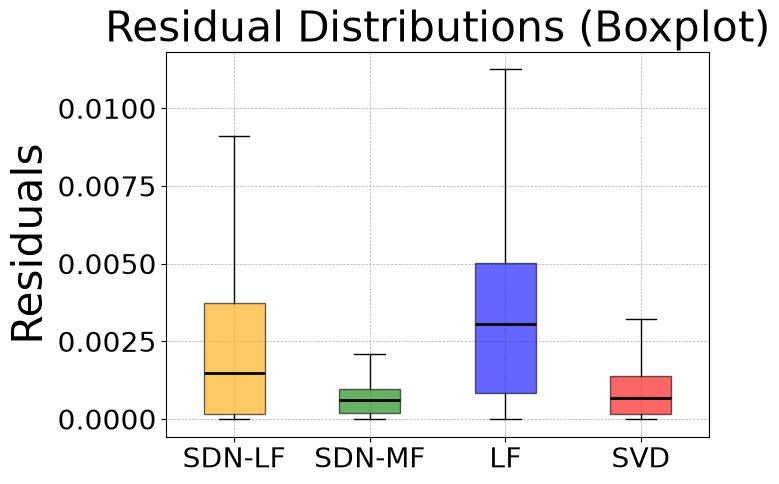

In [33]:
fig, axs = plt.subplots(1, 1, figsize=(7, 5))

# Custom colors matching KDE
colors = ['orange', 'green', 'blue', 'red']
labels = ['SDN-LF', 'SDN-MF', 'LF', 'SVD']

# Create boxplot with colorable patches
bp = axs.boxplot(
    [residual_field_sdn_lf, residual_field_sdn_mf, residual_field_lf, residual_field_svd],
    patch_artist=True,
    showfliers=False
)

# Apply colors
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)
    patch.set_edgecolor('black')
    patch.set_linewidth(1)

# Optional: color medians and whiskers to match
for median, color in zip(bp['medians'], colors):
    median.set_color('black')
    median.set_linewidth(2)

for whisker in bp['whiskers']:
    whisker.set_color('black')
    whisker.set_linewidth(1)

for cap in bp['caps']:
    cap.set_color('black')
    cap.set_linewidth(1)

axs.set_xticklabels(labels)
axs.set_ylabel('Residuals', fontsize=30)
axs.set_title('Residual Distributions (Boxplot)', fontsize=30)
axs.grid(True, which='both', linestyle='--', linewidth=0.5)
axs.tick_params(labelsize=20)